# Predicción de la dificultad de pago mediante modelos explicables

## Proyecto práctico de la Unidad 2 · Fase II

## <a id="indice"></a> Índice

- [0. Portada y objetivos](#sec-0)
  - [Datos del proyecto](#sec-0-datos-del-proyecto)
  - [Objetivo de predicción](#sec-0-objetivo-de-prediccion)
  - [Objetivos específicos](#sec-0-objetivos-especificos)
  - [Alcance](#sec-0-alcance)
  - [Guía del notebook](#sec-0-guia-del-notebook)
- [1. Entorno y reproducibilidad](#sec-1)
  - [1.1. Entorno de ejecución y dependencias](#sec-1-1)
  - [1.2. Importaciones, versiones y semillas](#sec-1-2)
  - [1.3. Localización y carga de archivos](#sec-1-3)
- [2. Descripción de los datos](#sec-2)
  - [2.1. Contexto y variable objetivo](#sec-2-1)
  - [2.2. Archivos y estructura](#sec-2-2)
  - [2.3. Diccionario de variables](#sec-2-3)
  - [2.4. Organización de los datos para el análisis](#sec-2-4)
- [3. Exploración y calidad de los datos](#sec-3)
  - [3.1. Distribución de la variable objetivo](#sec-3-1)
  - [3.2. Tipos de variables y valores ausentes](#sec-3-2)
  - [3.3. Identificadores y duplicados](#sec-3-3)
  - [3.4. Comprobaciones de dominio](#sec-3-4)
  - [3.5. Distribuciones de los predictores](#sec-3-5)
  - [3.6. Asociaciones y variables relacionadas](#sec-3-6)
  - [3.7. Revisión de posibles fugas de información](#sec-3-7)
  - [3.8. Síntesis de la exploración](#sec-3-8)
- [4. Diseño de la evaluación](#sec-4)
  - [4.1. Cinco particiones comunes](#sec-4-1)
  - [4.2. Métricas y criterio de selección](#sec-4-2)
  - [4.3. Referencia de la clase mayoritaria](#sec-4-3)
  - [4.4. Ajuste de configuraciones, variables y umbrales](#sec-4-4)
  - [4.5. Comparación y entrenamiento final](#sec-4-5)
- [5. Preprocesamiento](#sec-5)
  - [5.1. Decisiones de preprocesamiento](#sec-5-1)
  - [5.2. Codificación y escalado](#sec-5-2)
  - [5.3. Integración con los modelos](#sec-5-3)
  - [5.4. Comprobación en una partición](#sec-5-4)
  - [5.5. Uso en la validación cruzada](#sec-5-5)
- [6. Modelo lógico](#sec-6)
- [7. Regresión logística](#sec-7)
  - [7.1. Modelo y regularización](#sec-7-1)
  - [7.2. Configuraciones y criterios de selección](#sec-7-2)
  - [7.3. Evaluación anidada de cinco particiones](#sec-7-3)
  - [7.4. Resultados externos y efecto del umbral](#sec-7-4)
  - [7.5. Coeficientes, referencias y odds ratios](#sec-7-5)
  - [7.6. Visualización global de los coeficientes](#sec-7-6)
  - [7.7. Estabilidad entre las cinco particiones](#sec-7-7)
  - [7.8. Visualización con InterpretML](#sec-7-8)
  - [7.9. Síntesis de la interpretación y limitaciones](#sec-7-9)
- [8. Explainable Boosting Machine](#sec-8)
  - [8.1. Modelo aditivo y explicabilidad](#sec-8-1)
  - [8.2. Configuraciones y control del coste](#sec-8-2)
  - [8.3. Evaluación anidada de cinco particiones](#sec-8-3)
  - [8.4. Resultados externos y efecto del umbral](#sec-8-4)
  - [8.5. Primera exploración de las funciones aprendidas](#sec-8-5)
  - [8.6. Gráficas de todas las funciones univariantes](#sec-8-6)
  - [8.7. Variabilidad de las contribuciones globales](#sec-8-7)
  - [8.8. Comparación de las funciones en valores comunes](#sec-8-8)
  - [8.9. Síntesis de la interpretación y limitaciones](#sec-8-9)
- [9. Comparación del rendimiento](#sec-9)
- [10. Interpretación local comparada](#sec-10)
- [11. Discusión de las explicaciones](#sec-11)
- [12. Selección y entrenamiento final](#sec-12)
- [13. Predicción y exportación del test](#sec-13)
- [14. Conclusiones](#sec-14)
- [15. Referencias y uso de IA generativa](#sec-15)

## <a id="sec-0"></a> 0. Portada y objetivos

### <a id="sec-0-datos-del-proyecto"></a> Datos del proyecto

**Asignatura:** Inteligencia Artificial Explicable  
**Grupo:** 3  
**Repositorio:** [germansanchezz/iax-group-3](https://github.com/germansanchezz/iax-group-3)  
**Fecha de actualización:** 13 de octubre de 2026

**Integrantes:**

| Nombre | Correo electrónico |
| --- | --- |
| Damián Benasco Sánchez | d.benasco@alumnos.upm.es |
| Germán Sánchez Carmona | german.sanchez.carmona@alumnos.upm.es |
| Jorge Enrique Vega Ortiz | jorge.vega@alumnos.upm.es |

### <a id="sec-0-objetivo-de-prediccion"></a> Objetivo de predicción

Predecir la variable binaria `payment_difficulty_next_month`: **1 indica dificultad de pago en el mes siguiente y 0 indica ausencia de dificultad**, según el diccionario de datos. El propósito del proyecto es evaluar el rendimiento predictivo y comprender qué aprende cada modelo, explicar predicciones individuales y analizar coincidencias y discrepancias entre sus explicaciones.

### <a id="sec-0-objetivos-especificos"></a> Objetivos específicos

- Entrenar e interpretar las tres familias de modelos exigidas: un modelo lógico (árbol de decisión, lista de reglas o conjunto de reglas), una regresión logística y un modelo aditivo generalizado Explainable Boosting Machine (EBM) con `interactions=0`.
- Utilizar validación cruzada de cinco particiones para comparar modelos y seleccionar hiperparámetros, variables y umbrales de clasificación, con métricas elegidas y justificadas.
- Interpretar globalmente los modelos y comparar sus explicaciones locales sobre los mismos casos, incluyendo al menos un caso de cada clase.
- Examinar el equilibrio entre rendimiento, complejidad e interpretabilidad y distinguir las asociaciones aprendidas de las afirmaciones causales.
- Seleccionar una configuración mediante validación cruzada, entrenar el modelo final con todos los datos etiquetados y completar `test.csv` con una columna `predicted_class` de valores 0 o 1, conservando las filas y columnas originales.

### <a id="sec-0-alcance"></a> Alcance

Este notebook corresponde al proyecto completo de la Fase II descrito en [el enunciado](../project-statement-xai-2026.pdf). El análisis utilizará los datos etiquetados de `train.csv`, el conjunto sin etiquetas `test.csv` y las definiciones de `data-dictionary.xlsx`. La variable objetivo y algunas variables docentes son semisintéticas; las conclusiones se limitarán al ejercicio de predicción e interpretación y no se considerarán evidencia sobre una población real de crédito ni una política lista para su despliegue.

El notebook recogerá el análisis y la implementación reproducible, con ejecución de principio a fin en Google Colab. Los resultados y conclusiones se incorporarán cuando se completen las secciones correspondientes.

### <a id="sec-0-guia-del-notebook"></a> Guía del notebook

Las secciones 1–5 preparan el entorno, describen y exploran los datos, definen la evaluación y establecen el preprocesamiento. Las secciones 6–8 desarrollan e interpretan las tres familias de modelos. Las secciones 9–11 comparan el rendimiento, las explicaciones locales y sus limitaciones. Las secciones 12–13 seleccionan y entrenan el modelo final y exportan las predicciones del test. Las secciones 14–15 recogen las conclusiones, las referencias y el uso de IA generativa.


[Volver al índice](#indice)

## <a id="sec-1"></a> 1. Entorno y reproducibilidad

### <a id="sec-1-1"></a> 1.1. Entorno de ejecución y dependencias

El análisis se desarrolla en Python y está preparado para ejecutarse en un entorno local de Jupyter o en Google Colab. Se utilizan NumPy, pandas y SciPy para la manipulación de datos y el cálculo numérico; matplotlib para la visualización; scikit-learn e InterpretML para el entrenamiento y la interpretación de los modelos; y openpyxl para la lectura del diccionario de datos en Excel.

Las celdas deben ejecutarse en orden, desde un kernel limpio. La primera celda comprueba las dependencias e instala únicamente las ausentes. Las versiones de referencia identifican el entorno utilizado para verificar este apartado, mientras que el registro posterior recoge las versiones efectivamente utilizadas en cada ejecución.

Para reproducir una ejecución en otro entorno, se pueden instalar las versiones exactas del registro mediante `%pip install paquete==versión` y reiniciar el kernel antes de ejecutar el notebook completo. La instalación inicial requiere conexión a Internet.


In [1]:
import importlib
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

REFERENCE_VERSIONS = {
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "scipy": "1.15.3",
    "matplotlib": "3.10.9",
    "scikit-learn": "1.7.2",
    "interpret": "0.7.8",
    "openpyxl": "3.1.5",
}

missing_dependencies = []
for package, reference_version in REFERENCE_VERSIONS.items():
    try:
        version(package)
    except PackageNotFoundError:
        missing_dependencies.append(f"{package}=={reference_version}")

if missing_dependencies:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing_dependencies]
    )
    importlib.invalidate_caches()
    print("Dependencias ausentes instaladas.")
else:
    print("Todas las dependencias están instaladas.")

Todas las dependencias están instaladas.


### <a id="sec-1-2"></a> 1.2. Importaciones, versiones y semillas

Se importan las clases necesarias para los modelos lógicos, la regresión logística y Explainable Boosting Machine. La regresión logística se ajusta con scikit-learn; las herramientas de InterpretML permiten visualizar sus explicaciones globales y locales. Se configura `InlineProvider` para visualizar las explicaciones dentro del notebook, tanto en Jupyter como en Google Colab.

`SEED = 42` se utilizará también como `random_state` en los modelos y particiones que lo admitan. `N_JOBS = 1` fija un único proceso para las operaciones que admitan este parámetro. Las semillas por sí solas no garantizan resultados idénticos entre versiones, plataformas o implementaciones; por ello se registra también el entorno.

In [2]:
import hashlib
import platform
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from interpret import set_visualize_provider, show
from interpret.glassbox import (
    ClassificationTree,
    ExplainableBoostingClassifier,
    LogisticRegression,
)
from interpret.provider import InlineProvider

SEED = 42
N_JOBS = 1
random.seed(SEED)
np.random.seed(SEED)
set_visualize_provider(InlineProvider())

print(f"Python: {platform.python_version()}")
print(f"Plataforma: {platform.platform()}")
print(f"Semilla: {SEED} | Procesos: {N_JOBS}")

environment_versions = pd.DataFrame(
    [
        {
            "Paquete": package,
            "Versión instalada": version(package),
            "Versión de referencia": reference_version,
        }
        for package, reference_version in REFERENCE_VERSIONS.items()
    ]
)
display(environment_versions)

# Registro de versiones exactas para repetir esta ejecución.
print("Dependencias de esta ejecución:")
print("\n".join(f"{package}=={version(package)}" for package in REFERENCE_VERSIONS))

Python: 3.10.21
Plataforma: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.43
Semilla: 42 | Procesos: 1


,Paquete,Versión instalada,Versión de referencia
0,numpy,2.2.6,2.2.6
1,pandas,2.3.3,2.3.3
2,scipy,1.15.3,1.15.3
3,matplotlib,3.10.9,3.10.9
4,scikit-learn,1.7.2,1.7.2
5,interpret,0.7.8,0.7.8
6,openpyxl,3.1.5,3.1.5


Dependencias de esta ejecución:
numpy==2.2.6
pandas==2.3.3
scipy==1.15.3
matplotlib==3.10.9
scikit-learn==1.7.2
interpret==0.7.8
openpyxl==3.1.5


### <a id="sec-1-3"></a> 1.3. Localización y carga de archivos

Se necesitan `train.csv`, `test.csv` y `data-dictionary.xlsx`. En el repositorio se buscan en `data/`, tanto si el kernel se inicia en la raíz como en `notebooks/`. También se admite que los tres archivos estén en el directorio de ejecución.

En Google Colab, si no se encuentran los archivos, se abrirá el selector para subir los tres. Si están en Google Drive, montar primero la unidad con `from google.colab import drive; drive.mount('/content/drive')` y establecer `DATA_DIR_OVERRIDE` con la ruta de su carpeta. La ruta explícita tiene prioridad; si está incompleta, se mostrará qué archivos faltan.

Se cargan los CSV en `train_raw` y `test_raw`, y todas las hojas del Excel en `dictionary_sheets`. Se conserva `row_id` como texto para mantener los identificadores. En este apartado no se transforman las variables ni se ajustan modelos. La tabla de archivos registra su tamaño y huella SHA-256 para comprobar que distintas ejecuciones utilizan los mismos datos.

In [3]:
# Ejemplo en Drive: Path("/content/drive/MyDrive/proyecto_xai/data")
DATA_DIR_OVERRIDE = None
REQUIRED_FILES = ("train.csv", "test.csv", "data-dictionary.xlsx")

if DATA_DIR_OVERRIDE is not None:
    data_dir = Path(DATA_DIR_OVERRIDE).expanduser().resolve()
else:
    working_dir = Path.cwd().resolve()
    candidates = [working_dir / "data", working_dir.parent / "data", working_dir]
    data_dir = next(
        (directory for directory in candidates
         if all((directory / name).is_file() for name in REQUIRED_FILES)),
        None,
    )
    if data_dir is None and "google.colab" in sys.modules:
        from google.colab import files

        print("Sube train.csv, test.csv y data-dictionary.xlsx.")
        uploaded_files = files.upload()
        data_dir = working_dir

if data_dir is None:
    raise FileNotFoundError(
        "No se encontró una carpeta con los tres archivos. "
        "Establece DATA_DIR_OVERRIDE con la ruta de la carpeta de datos."
    )

missing_files = [name for name in REQUIRED_FILES if not (data_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Faltan archivos en {data_dir}: {', '.join(missing_files)}")

train_raw = pd.read_csv(data_dir / "train.csv", dtype={"row_id": "string"})
test_raw = pd.read_csv(data_dir / "test.csv", dtype={"row_id": "string"})
dictionary_sheets = pd.read_excel(
    data_dir / "data-dictionary.xlsx", sheet_name=None, engine="openpyxl"
)

file_manifest = pd.DataFrame(
    [
        {
            "Archivo": name,
            "Bytes": (data_dir / name).stat().st_size,
            "SHA-256": hashlib.sha256((data_dir / name).read_bytes()).hexdigest(),
        }
        for name in REQUIRED_FILES
    ]
)
print(f"Carpeta de datos: {data_dir}")
display(file_manifest)
print(f"train_raw: {train_raw.shape[0]} filas × {train_raw.shape[1]} columnas")
print(f"test_raw: {test_raw.shape[0]} filas × {test_raw.shape[1]} columnas")
print(f"Hojas del diccionario: {', '.join(dictionary_sheets)}")

Carpeta de datos: /home/german/master-ia/iax/iax-group-3/data


,Archivo,Bytes,SHA-256
0,train.csv,2202681,80abfae992397f7869cb712ed7aef11988a584fe0edc0b...
1,test.csv,430761,1d07915ab453c8bf1e174647e358ae041e36ec6596826a...
2,data-dictionary.xlsx,10469,bebaedc4e865295d983cbae46356039852379b78575db1...


train_raw: 25000 filas × 17 columnas
test_raw: 5000 filas × 16 columnas
Hojas del diccionario: Data dictionary, Domain context


[Volver al índice](#indice)

## <a id="sec-2"></a> 2. Descripción de los datos

### <a id="sec-2-1"></a> 2.1. Contexto y variable objetivo

Los datos describen registros de clientes de una cartera de crédito: límite de crédito, características demográficas y resúmenes de facturación, pagos y retrasos durante los seis meses anteriores al mes del resultado. Según [el diccionario de datos](../data/data-dictionary.xlsx), la fuente original es *Default of Credit Card Clients*, de Yeh y Lien, disponible en UCI (DOI: `10.24432/C55S3H`). La variable objetivo y algunas variables del ejercicio son semisintéticas; por tanto, no debe equipararse este conjunto con la versión original de UCI.

La tarea es una **clasificación binaria** de `payment_difficulty_next_month`:

- **Clase 0:** ausencia de dificultad de pago en el mes siguiente.
- **Clase 1:** presencia de dificultad de pago en el mes siguiente.

La clase 1 se considera la clase positiva. El objetivo es anticipar el resultado del mes siguiente a partir de información anterior a ese resultado. Cada fila representa un registro identificado por `row_id`; el diccionario no permite afirmar que haya un único registro por persona.

Los resultados describirán asociaciones predictivas dentro de este conjunto semisintético. No identificarán efectos causales ni constituirán evidencia suficiente para implantar una política de crédito.

### <a id="sec-2-2"></a> 2.2. Archivos y estructura

`train.csv` contiene los registros etiquetados para desarrollar, comparar y entrenar los modelos. `test.csv` contiene registros sin la variable objetivo y se reserva para producir las predicciones finales. El diccionario Excel incluye las hojas `Data dictionary`, con las definiciones de variables, y `Domain context`, con su contexto temporal y las precauciones de interpretación.

La siguiente celda calcula los tamaños a partir de los archivos cargados en el apartado 1 y comprueba la estructura básica: presencia del identificador y del objetivo en entrenamiento, ausencia del objetivo en test y coincidencia de las columnas predictoras. La calidad de los valores y la distribución de clases se estudiarán en el apartado 3.

In [4]:
TARGET = "payment_difficulty_next_month"
ID_COLUMN = "row_id"
PREDICTION_COLUMN = "predicted_class"

for name, frame in (("train.csv", train_raw), ("test.csv", test_raw)):
    if ID_COLUMN not in frame.columns:
        raise ValueError(f"Falta {ID_COLUMN} en {name}.")
if TARGET not in train_raw.columns:
    raise ValueError(f"Falta la variable objetivo {TARGET} en train.csv.")
if TARGET in test_raw.columns:
    raise ValueError("Se esperaba un test sin la variable objetivo.")
if PREDICTION_COLUMN in train_raw.columns or PREDICTION_COLUMN in test_raw.columns:
    raise ValueError("Utiliza los archivos originales, sin la columna de predicciones.")

feature_columns = [
    column for column in train_raw.columns if column not in (ID_COLUMN, TARGET)
]
test_feature_columns = [column for column in test_raw.columns if column != ID_COLUMN]
if set(feature_columns) != set(test_feature_columns):
    raise ValueError("Las columnas predictoras de entrenamiento y test no coinciden.")

# Los tamaños se obtienen de los archivos, sin fijarlos manualmente.
dataset_summary = pd.DataFrame(
    [
        {
            "Archivo": name,
            "Filas": len(frame),
            "Columnas totales": frame.shape[1],
            "Predictores candidatos": len(feature_columns),
            "Identificador": ID_COLUMN,
            "Variable objetivo": TARGET if TARGET in frame.columns else "No incluida",
            "Uso": purpose,
        }
        for name, frame, purpose in (
            ("train.csv", train_raw, "Desarrollo, validación cruzada y entrenamiento final"),
            ("test.csv", test_raw, "Predicción final; sin etiquetas para evaluar"),
        )
    ]
)
display(dataset_summary)
print("Hojas del diccionario:", ", ".join(dictionary_sheets))

,Archivo,Filas,Columnas totales,Predictores candidatos,Identificador,Variable objetivo,Uso
0,train.csv,25000,17,15,row_id,payment_difficulty_next_month,"Desarrollo, validación cruzada y entrenamiento..."
1,test.csv,5000,16,15,row_id,No incluida,Predicción final; sin etiquetas para evaluar


Hojas del diccionario: Data dictionary, Domain context


La vista de las primeras filas permite reconocer cómo se representan las variables en los CSV. Es una muestra de la estructura, no un resumen estadístico del conjunto.

In [5]:
print("Primeras filas del conjunto etiquetado:")
display(train_raw.head())
print("Primeras filas del conjunto sin etiquetas:")
display(test_raw.head())

Primeras filas del conjunto etiquetado:


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,payment_difficulty_next_month
0,CR26-120473,80000,male,university,married,54,0,0,0,24600,3700,10300,0.07,0,0.33,no,0
1,CR26-127004,20000,male,university,single,30,0,0,0,21100,21000,6700,0.05,0,1.98,no,0
2,CR26-116408,230000,female,graduate_school,married,35,0,0,0,1700,3600,5100,0.49,1,0.03,no,0
3,CR26-125768,150000,female,university,married,51,0,0,0,76100,-8800,15400,0.03,0,0.48,no,0
4,CR26-118040,500000,male,graduate_school,married,43,0,0,0,121600,26200,25000,0.03,0,0.25,yes,0


Primeras filas del conjunto sin etiquetas:


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan
0,CR26-128173,50000,male,graduate_school,single,25,0,0,0,27700,31600,21700,0.13,0,0.80,no
1,CR26-102911,280000,female,university,married,41,1,1,1,100,300,600,0.63,4,0.00,no
2,CR26-104960,420000,male,university,married,38,0,0,0,262500,108200,56200,0.04,0,0.70,no
3,CR26-123913,270000,male,university,single,44,0,0,0,247400,48900,56400,0.04,0,1.02,no
4,CR26-111750,120000,female,graduate_school,single,29,-1,0,0,1700,-2100,12000,1.20,0,0.00,yes


### <a id="sec-2-3"></a> 2.3. Diccionario de variables

La siguiente tabla resume las definiciones del diccionario proporcionado. **NTD** corresponde al dólar taiwanés. Los tipos descritos son semánticos: una variable almacenada como número puede representar un código y no una magnitud continua.

| Variable | Papel y tipo | Significado y observaciones |
| --- | --- | --- |
| `row_id` | Identificador, texto | Identificador opaco para alinear los registros y las predicciones. Se conserva para la exportación y se excluye de los predictores. |
| `credit_limit` | Predictor, entero | Límite de crédito registrado, en NTD. |
| `sex` | Predictor y atributo de auditoría, categórica | Sexo registrado: `female` o `male`. La fuente solo recoge estas dos categorías. Permite una auditoría descriptiva de subgrupos; su inclusión como predictor deberá justificarse. |
| `education` | Predictor, categórica | Grupo de educación registrado. Los códigos no documentados se agrupan en `unknown`. |
| `marital_status` | Predictor, categórica | Estado civil registrado. Los códigos no documentados y otras categorías se agrupan en `other_or_unknown`. |
| `age` | Predictor, entero | Edad en años en el momento del registro de crédito. |
| `latest_repayment_status` | Predictor, código entero | Estado de pago más reciente. Los valores positivos indican meses de retraso; no se atribuirá un significado específico a los códigos negativos o cero, que no están completamente documentados. |
| `maximum_repayment_delay_6m` | Predictor, entero | Máximo retraso positivo durante seis meses, en meses. Los códigos de estado no positivos contribuyen con cero al agregado. |
| `delayed_months_6m` | Predictor, entero | Número de meses con código de retraso positivo durante seis meses; rango de 0 a 6. |
| `average_bill_6m` | Predictor, entero | Facturación media durante seis meses, en NTD, redondeada a centenas. |
| `bill_change_sep_to_apr` | Predictor, entero | Factura de septiembre menos factura de abril, en NTD, redondeada a centenas. Un valor positivo indica mayor facturación en septiembre. |
| `total_payment_6m` | Predictor, entero | Total pagado durante seis meses, en NTD, redondeado a centenas. |
| `payment_to_bill_ratio_6m` | Predictor, real | Total pagado en seis meses dividido por la suma de las facturas positivas. El denominador tiene un mínimo de 1.000 NTD y el cociente un máximo de 5. Valores altos pueden reflejar pagos extraordinarios o facturas pequeñas; no se presupone una relación lineal con el riesgo. |
| `zero_payment_months_6m` | Predictor, entero | Número de meses con pago registrado igual a cero durante seis meses; rango de 0 a 6. Un mes sin pago no tiene necesariamente la misma implicación que varios meses consecutivos o repetidos. |
| `utilization_sep` | Predictor, real | Factura de septiembre dividida por el límite de crédito. Se limita al intervalo de 0 a 2 y se redondea a dos decimales. |
| `repayment_assistance_plan` | Predictor, categórica | Registro de un plan temporal de apoyo al pago o reestructuración anterior al mes del resultado. Su asignación es selectiva y puede responder a signos previos de dificultad financiera. |
| `payment_difficulty_next_month` | Objetivo, binaria | Indicador semisintético de dificultad de pago en el mes siguiente: 1 significa sí y 0 significa no. Solo se incluye en entrenamiento. |
| `predicted_class` | Salida de entrega, binaria | Etiqueta predicha, con valores 0 o 1, que se añadirá al test en la exportación final. No es una variable de entrada. |

La siguiente celda vincula los nombres presentes en los CSV con el diccionario y muestra el tipo de almacenamiento detectado por pandas junto al tipo semántico documentado. El diccionario incluye `predicted_class`, aunque esta columna todavía no está en los archivos originales.

In [6]:
data_dictionary = dictionary_sheets["Data dictionary"].copy()
required_dictionary_columns = {"variable", "role", "type", "units", "description", "notes"}
if not required_dictionary_columns.issubset(data_dictionary.columns):
    raise ValueError("El diccionario no contiene las columnas esperadas.")

undocumented_columns = set(train_raw.columns) - set(data_dictionary["variable"])
if undocumented_columns:
    raise ValueError(f"Variables no documentadas: {sorted(undocumented_columns)}")

variable_schema = data_dictionary[["variable", "role", "type", "units"]].copy()
variable_schema["En entrenamiento"] = variable_schema["variable"].isin(train_raw.columns)
variable_schema["En test original"] = variable_schema["variable"].isin(test_raw.columns)
variable_schema["Tipo en pandas (train)"] = variable_schema["variable"].map(
    train_raw.dtypes.astype(str).to_dict()
).fillna("No incluida")
variable_schema = variable_schema.rename(
    columns={"variable": "Variable", "role": "Papel documentado",
             "type": "Tipo semántico", "units": "Unidad"}
)
variable_schema["Unidad"] = variable_schema["Unidad"].fillna("No aplicable")
display(variable_schema)

,Variable,Papel documentado,Tipo semántico,Unidad,En entrenamiento,En test original,Tipo en pandas (train)
0,row_id,identifier,text,No aplicable,True,True,string
1,credit_limit,predictor,integer,NTD,True,True,int64
2,sex,predictor / audit attribute,categorical,No aplicable,True,True,object
3,education,predictor,categorical,No aplicable,True,True,object
4,marital_status,predictor,categorical,No aplicable,True,True,object
5,age,predictor,integer,years,True,True,int64
6,latest_repayment_status,predictor,integer code,No aplicable,True,True,int64
7,maximum_repayment_delay_6m,predictor,integer,months,True,True,int64
8,delayed_months_6m,predictor,integer,months,True,True,int64
9,average_bill_6m,predictor,integer,NTD,True,True,int64


### <a id="sec-2-4"></a> 2.4. Organización de los datos para el análisis

Se separan los predictores candidatos (`X_raw`), las etiquetas (`y`) y los predictores del test (`X_test_raw`). Se excluyen `row_id` y la variable objetivo de las entradas de los modelos, y se conserva el mismo orden de columnas predictoras en ambos conjuntos. Los identificadores del test se guardan por separado para comprobar la alineación durante la exportación. Esta separación no aplica imputación, codificación, escalado ni selección de variables.

El contexto temporal distingue los seis meses de comportamiento previo, el posible plan de asistencia anterior al resultado y la dificultad de pago del mes siguiente. Que el plan de asistencia se asocie con mayor riesgo no implica que lo cause: puede ofrecerse precisamente a clientes que ya muestran dificultades. Asimismo, comparar errores entre categorías de `sex` permitirá describir diferencias, pero no bastará por sí solo para establecer equidad o inequidad.

El test no proporciona etiquetas con las que calcular métricas. Las decisiones sobre modelos, variables, hiperparámetros y umbrales se basarán en la validación cruzada del conjunto etiquetado. La distribución de clases, los valores ausentes, los duplicados y las posibles fugas de información se examinarán en el siguiente apartado.

In [7]:
X_raw = train_raw.loc[:, feature_columns].copy()
y = train_raw[TARGET].copy()
X_test_raw = test_raw.loc[:, feature_columns].copy()
test_row_ids = test_raw[ID_COLUMN].copy()

print(f"X_raw: {X_raw.shape} | y: {y.shape}")
print(f"X_test_raw: {X_test_raw.shape}")
print("Predictores candidatos:", ", ".join(feature_columns))

X_raw: (25000, 15) | y: (25000,)
X_test_raw: (5000, 15)
Predictores candidatos: credit_limit, sex, education, marital_status, age, latest_repayment_status, maximum_repayment_delay_6m, delayed_months_6m, average_bill_6m, bill_change_sep_to_apr, total_payment_6m, payment_to_bill_ratio_6m, zero_payment_months_6m, utilization_sep, repayment_assistance_plan


[Volver al índice](#indice)

## <a id="sec-3"></a> 3. Exploración y calidad de los datos

La exploración busca conocer la distribución de clases, detectar problemas de calidad y reconocer patrones que puedan afectar al entrenamiento o a la interpretación. El análisis de distribuciones y asociaciones se realiza sobre el conjunto etiquetado. El test se utiliza aquí únicamente para comprobar su integridad y compatibilidad con entrenamiento, sin orientar la selección de modelos o transformaciones.

### <a id="sec-3-1"></a> 3.1. Distribución de la variable objetivo

Se comprueba que todas las etiquetas estén presentes y sean 0 o 1. La tabla y el gráfico muestran cuántos registros pertenecen a cada clase. La proporción mayoritaria permite contextualizar la exactitud: un clasificador que siempre predijera esa clase obtendría esa exactitud en estos datos, aunque no detectaría ningún caso de la otra clase. Las métricas de evaluación se definirán en el apartado 4.

,Registros,Porcentaje
Clase,,
0,19697,78.79
1,5303,21.21


Exactitud de predecir siempre la clase mayoritaria: 78.79%


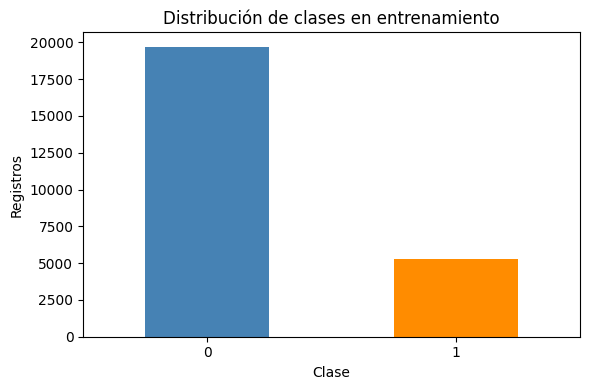

In [8]:
if y.isna().any() or not y.isin([0, 1]).all():
    raise ValueError("La variable objetivo contiene etiquetas ausentes o distintas de 0 y 1.")

class_counts = y.value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    "Registros": class_counts,
    "Porcentaje": (class_counts / len(y) * 100).round(2),
})
class_summary.index.name = "Clase"
display(class_summary)
print(f"Exactitud de predecir siempre la clase mayoritaria: {class_counts.max() / len(y):.2%}")

ax = class_counts.plot.bar(color=["steelblue", "darkorange"], rot=0, figsize=(6, 4))
ax.set(title="Distribución de clases en entrenamiento", xlabel="Clase", ylabel="Registros")
plt.tight_layout()
plt.show()

La comprobación confirma que las etiquetas son válidas y están completas. De los 25.000 registros, **19.697 pertenecen a la clase 0 (78,79 %) y 5.303 a la clase 1 (21,21 %)**. Existe desequilibrio de clases: predecir siempre 0 alcanzaría un 78,79 % de exactitud en este conjunto sin detectar ningún caso de dificultad de pago. Por ello, la evaluación deberá considerar también la capacidad de reconocer la clase positiva y el comportamiento en ambas clases.

### <a id="sec-3-2"></a> 3.2. Tipos de variables y valores ausentes

Se identifican las variables numéricas y categóricas según su almacenamiento en pandas. Esta clasificación inicial se interpreta junto al diccionario: `latest_repayment_status` es un código entero, y las variables de recuento tienen dominios discretos.

La tabla de calidad muestra, para cada columna de ambos archivos, su tipo, número de valores distintos y valores ausentes. Los niveles `unknown` y `other_or_unknown` son categorías documentadas, no valores ausentes de pandas; su frecuencia se mostrará en la exploración categórica. También se comprueba la presencia de valores infinitos en los predictores numéricos.

In [9]:
numeric_features = X_raw.select_dtypes(include="number").columns.tolist()
categorical_features = [column for column in feature_columns if column not in numeric_features]

print("Variables numéricas:", ", ".join(numeric_features))
print("Variables categóricas:", ", ".join(categorical_features))

quality_tables = []
for name, frame in (("train.csv", train_raw), ("test.csv", test_raw)):
    quality = pd.DataFrame({
        "Tipo": frame.dtypes.astype(str),
        "Valores distintos (sin ausentes)": frame.nunique(),
        "Ausentes": frame.isna().sum(),
        "Ausentes (%)": (frame.isna().mean() * 100).round(2),
    })
    quality["Infinitos"] = 0
    quality.loc[numeric_features, "Infinitos"] = np.isinf(frame[numeric_features]).sum()
    quality_tables.append(quality)

quality_summary = pd.concat(quality_tables, keys=["train.csv", "test.csv"], names=["Archivo", "Variable"])
display(quality_summary)

Variables numéricas: credit_limit, age, latest_repayment_status, maximum_repayment_delay_6m, delayed_months_6m, average_bill_6m, bill_change_sep_to_apr, total_payment_6m, payment_to_bill_ratio_6m, zero_payment_months_6m, utilization_sep
Variables categóricas: sex, education, marital_status, repayment_assistance_plan


Tipo  \
Archivo   Variable                                 
train.csv row_id                          string   
          credit_limit                     int64   
          sex                             object   
          education                       object   
          marital_status                  object   
          age                              int64   
          latest_repayment_status          int64   
          maximum_repayment_delay_6m       int64   
          delayed_months_6m                int64   
          average_bill_6m                  int64   
          bill_change_sep_to_apr           int64   
          total_payment_6m                 int64   
          payment_to_bill_ratio_6m       float64   
          zero_payment_months_6m           int64   
          utilization_sep                float64   
          repayment_assistance_plan       object   
          payment_difficulty_next_month    int64   
test.csv  row_id                          string   
          credit_limit                     int64   
          sex                             object   
          education                       object   
          marital_status                  object   
          age                              int64   
          latest_repayment_status          int64   
          maximum_repayment_delay_6m       int64   
          delayed_months_6m                int64   
          average_bill_6m                  int64   
          bill_change_sep_to_apr           int64   
          total_payment_6m                 int64   
          payment_to_bill_ratio_6m       float64   
          zero_payment_months_6m           int64   
          utilization_sep                float64   
          repayment_assistance_plan       object   

                                         Valores distintos (sin ausentes)  \
Archivo   Variable                                                          
train.csv row_id                                                    25000   
          credit_limit                                                 80   
          sex                                                           2   
          education                                                     5   
          marital_status                                                3   
          age                                                          56   
          latest_repayment_status                                      11   
          maximum_repayment_delay_6m                                    9   
          delayed_months_6m                                             7   
          average_bill_6m                                            2592   
          bill_change_sep_to_apr                                     2549   
          total_payment_6m                                           2055   
          payment_to_bill_ratio_6m                                    349   
          zero_payment_months_6m                                        7   
          utilization_sep                                             195   
          repayment_assistance_plan                                     2   
          payment_difficulty_next_month                                 2   
test.csv  row_id                                                     5000   
          credit_limit                                                 69   
          sex                                                           2   
          education                                                     5   
          marital_status                                                3   
          age                                                          52   
          latest_repayment_status                                      11   
          maximum_repayment_delay_6m                                    9   
          delayed_months_6m                                             7   
          average_bill_6m                                          

Los 15 predictores se distribuyen en **11 variables numéricas y 4 categóricas**. No se detectan valores ausentes en ninguna columna de entrenamiento o test, ni infinitos en los predictores numéricos. Estos archivos no requieren corregir ausentes observados; si se incluye imputación en el pipeline, deberá explicarse su finalidad. Los códigos `unknown` y `other_or_unknown` permanecen como categorías explícitas y no se confunden con valores nulos.

### <a id="sec-3-3"></a> 3.3. Identificadores y duplicados

Se distinguen filas completamente duplicadas, identificadores repetidos y perfiles con los mismos predictores. Los conteos de duplicados indican repeticiones posteriores a la primera aparición. Dos registros con los mismos predictores no demuestran que correspondan a la misma persona; no se eliminarán automáticamente.

Se comprueba además si hay identificadores compartidos entre entrenamiento y test y si un mismo perfil de predictores aparece con etiquetas diferentes. Los identificadores compartidos o repetidos requerirían revisar la separación de los conjuntos. Los perfiles repetidos requerirían valorar si pueden aparecer a ambos lados de una partición de validación; las etiquetas diferentes no implican necesariamente un error, pues la información disponible puede ser insuficiente para determinar el resultado.

In [10]:
duplicate_summary = pd.DataFrame([
    {
        "Archivo": name,
        "Filas duplicadas completas": int(frame.duplicated().sum()),
        "Identificadores repetidos (sin ausentes)": int(frame[ID_COLUMN].dropna().duplicated().sum()),
        "Perfiles de predictores repetidos": int(frame.duplicated(subset=feature_columns).sum()),
    }
    for name, frame in (("train.csv", train_raw), ("test.csv", test_raw))
])
display(duplicate_summary)

shared_ids = set(train_raw[ID_COLUMN].dropna()) & set(test_raw[ID_COLUMN].dropna())
labels_per_profile = train_raw.groupby(feature_columns, dropna=False)[TARGET].nunique()
print("Identificadores distintos compartidos entre train y test:", len(shared_ids))
print("Perfiles con etiquetas diferentes:", int((labels_per_profile > 1).sum()))

,Archivo,Filas duplicadas completas,Identificadores repetidos (sin ausentes),Perfiles de predictores repetidos
0,train.csv,0,0,31
1,test.csv,0,0,0


Identificadores distintos compartidos entre train y test: 0
Perfiles con etiquetas diferentes: 13


No hay filas completas duplicadas ni identificadores repetidos en ninguno de los conjuntos, y no hay identificadores compartidos entre entrenamiento y test. En entrenamiento se detectan **31 repeticiones de perfiles de predictores posteriores a su primera aparición**; esta cifra no representa 31 personas duplicadas ni necesariamente 31 perfiles distintos. El test no presenta repeticiones de perfiles dentro de su propio conjunto.

Además, **13 perfiles distintos aparecen con etiquetas diferentes**. Esto indica que los predictores disponibles no determinan de forma única todas las etiquetas observadas; no basta para afirmar que sean errores de etiquetado. Se conservan los registros. En el diseño de la evaluación deberá valorarse la presencia de perfiles repetidos, sin asumir que pertenezcan a la misma persona. Esta comprobación no ha contrastado la coincidencia de perfiles entre entrenamiento y test.

### <a id="sec-3-4"></a> 3.4. Comprobaciones de dominio

Se revisan los límites expresamente documentados: recuentos de meses entre 0 y 6, cociente de pagos entre 0 y 5 y utilización entre 0 y 2. Los recuentos de meses deben ser enteros, y el retraso máximo debe ser un entero no negativo. Se comprueban también las categorías documentadas de `sex`. Los valores ausentes se contabilizan en la tabla anterior y no se cuentan como incumplimientos de dominio.

No se consideran errores los códigos negativos de `latest_repayment_status`, los importes negativos de facturación ni los valores extremos por el mero hecho de ser poco frecuentes. Su interpretación exige atender al significado de cada variable. Esta revisión tampoco certifica la calidad completa del conjunto: comprueba solo las condiciones indicadas.

In [11]:
bounded_domains = {
    "delayed_months_6m": (0, 6),
    "zero_payment_months_6m": (0, 6),
    "payment_to_bill_ratio_6m": (0, 5),
    "utilization_sep": (0, 2),
}
integer_counts = ["delayed_months_6m", "zero_payment_months_6m", "maximum_repayment_delay_6m"]
domain_results = []
for name, frame in (("train.csv", train_raw), ("test.csv", test_raw)):
    for column, (lower, upper) in bounded_domains.items():
        values = frame[column].dropna()
        domain_results.append({"Archivo": name, "Variable": column,
                               "Comprobación": f"Intervalo [{lower}, {upper}]",
                               "Incumplimientos": int((~values.between(lower, upper)).sum())})
    for column in integer_counts:
        values = frame[column].dropna()
        invalid = (values < 0) | (values % 1 != 0)
        domain_results.append({"Archivo": name, "Variable": column,
                               "Comprobación": "Entero no negativo",
                               "Incumplimientos": int(invalid.sum())})
    invalid_sex = frame["sex"].notna() & ~frame["sex"].isin(["female", "male"])
    domain_results.append({"Archivo": name, "Variable": "sex",
                           "Comprobación": "female o male",
                           "Incumplimientos": int(invalid_sex.sum())})

domain_summary = pd.DataFrame(domain_results)
display(domain_summary)

,Archivo,Variable,Comprobación,Incumplimientos
0,train.csv,delayed_months_6m,"Intervalo [0, 6]",0
1,train.csv,zero_payment_months_6m,"Intervalo [0, 6]",0
2,train.csv,payment_to_bill_ratio_6m,"Intervalo [0, 5]",0
3,train.csv,utilization_sep,"Intervalo [0, 2]",0
4,train.csv,delayed_months_6m,Entero no negativo,0
5,train.csv,zero_payment_months_6m,Entero no negativo,0
6,train.csv,maximum_repayment_delay_6m,Entero no negativo,0
7,train.csv,sex,female o male,0
8,test.csv,delayed_months_6m,"Intervalo [0, 6]",0
9,test.csv,zero_payment_months_6m,"Intervalo [0, 6]",0


Todas las comprobaciones de dominio arrojan **cero incumplimientos** en entrenamiento y test. Los recuentos revisados son enteros no negativos y las variables acotadas respetan los intervalos documentados. No se identifica ninguna corrección necesaria a partir de estas reglas; el resultado no certifica la ausencia de otros problemas de calidad.

### <a id="sec-3-5"></a> 3.5. Distribuciones de los predictores

El resumen numérico muestra los rangos y las diferencias de escala; los histogramas permiten observar asimetrías, concentraciones y valores extremos. En variables discretas, las barras deben interpretarse como agrupaciones de valores, no como evidencia de continuidad. Estos gráficos no justifican por sí solos recortar valores o suponer una relación lineal con la dificultad de pago.

,count,mean,std,min,25%,50%,75%,max
credit_limit,25000.0,167740.95,129975.98,10000.0,50000.00,140000.00,240000.00,1000000.0
age,25000.0,35.50,9.24,21.0,28.00,34.00,41.00,79.0
latest_repayment_status,25000.0,-0.02,1.12,-2.0,-1.00,0.00,0.00,8.0
maximum_repayment_delay_6m,25000.0,0.68,1.07,0.0,0.00,0.00,2.00,8.0
delayed_months_6m,25000.0,0.83,1.55,0.0,0.00,0.00,1.00,6.0
average_bill_6m,25000.0,44910.44,63267.26,-56000.0,4700.00,21000.00,57100.00,877300.0
bill_change_sep_to_apr,25000.0,12389.51,44068.85,-403600.0,-3000.00,900.00,19900.00,708300.0
total_payment_6m,25000.0,31635.05,57337.82,0.0,6700.00,14400.00,33700.00,2314200.0
payment_to_bill_ratio_6m,25000.0,0.37,0.59,0.0,0.04,0.09,0.60,5.0
zero_payment_months_6m,25000.0,1.23,1.72,0.0,0.00,0.00,2.00,6.0


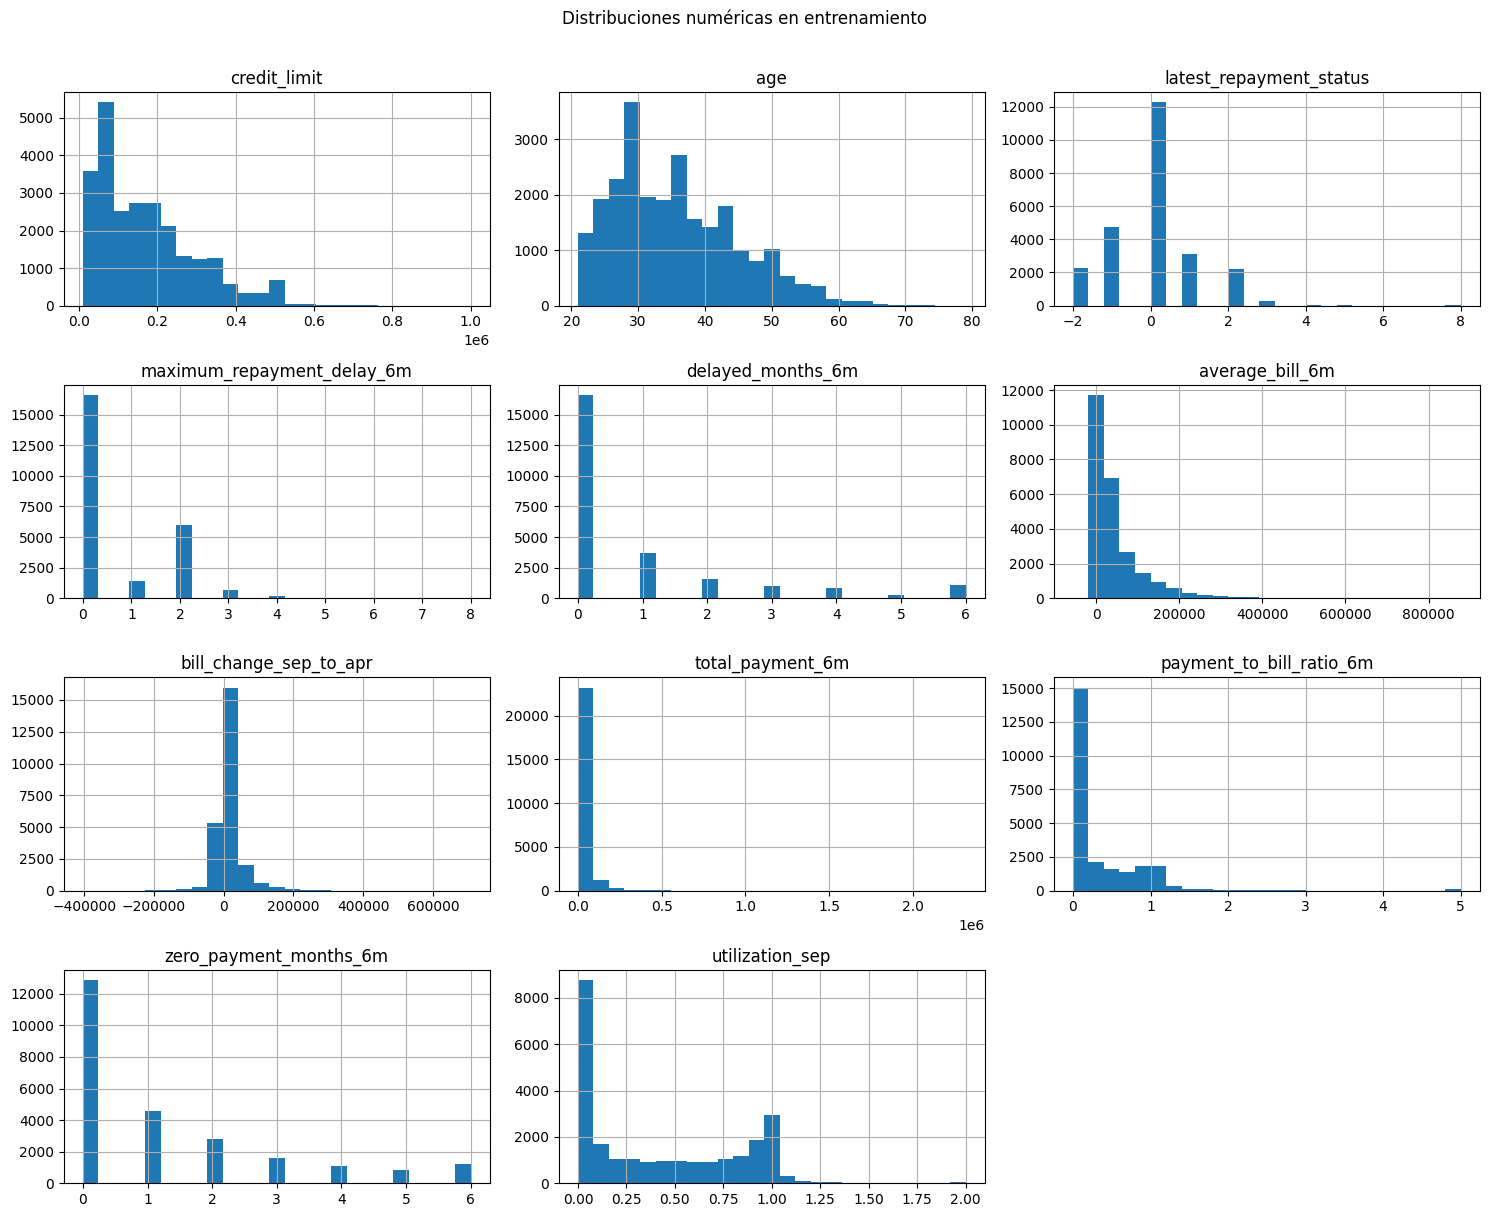

In [12]:
numeric_summary = X_raw[numeric_features].describe().T
display(numeric_summary.round(2))

X_raw[numeric_features].hist(bins=25, figsize=(15, 12), layout=(-1, 3))
plt.suptitle("Distribuciones numéricas en entrenamiento", y=1.01)
plt.tight_layout()
plt.show()

Los histogramas muestran asimetría hacia valores altos en varios importes monetarios. Por ejemplo, `total_payment_6m` tiene una mediana de **14.400 NTD**, una media de **31.635,05 NTD** y un máximo de **2.314.200 NTD**; unos pocos importes elevados amplían considerablemente el rango. `average_bill_6m` presenta también una media (44.910,44 NTD) superior a su mediana (21.000 NTD). No se eliminarán estos extremos sin una justificación adicional.

Las escalas difieren mucho: `credit_limit` va de 10.000 a 1.000.000 NTD, mientras que `payment_to_bill_ratio_6m` va de 0 a 5. Esta diferencia deberá tenerse en cuenta al preparar la regresión logística regularizada. Las variables de retraso concentran numerosos registros en cero, y los códigos de `latest_repayment_status` abarcan de −2 a 8; no se asigna un significado adicional a sus códigos no positivos. Los valores negativos de facturación y de su cambio se mantienen, pues estas comprobaciones no demuestran que sean errores.

Para las variables categóricas se muestran todos los niveles y sus frecuencias, incluyendo los ausentes si los hubiera. Las categorías con pocos registros pueden dar lugar a estimaciones menos estables; cualquier agrupación posterior deberá justificarse y evaluarse dentro de la validación cruzada.

In [13]:
categorical_tables = []
for column in categorical_features:
    counts = X_raw[column].value_counts(dropna=False)
    table = counts.rename_axis("Categoría").reset_index(name="Registros")
    table.insert(0, "Variable", column)
    table["Porcentaje"] = (table["Registros"] / len(X_raw) * 100).round(2)
    categorical_tables.append(table)

categorical_summary = pd.concat(categorical_tables, ignore_index=True)
display(categorical_summary)

,Variable,Categoría,Registros,Porcentaje
0,sex,female,15130,60.52
1,sex,male,9870,39.48
2,education,university,11675,46.70
3,education,graduate_school,8820,35.28
4,education,high_school,4107,16.43
5,education,unknown,289,1.16
6,education,other,109,0.44
7,marital_status,single,13310,53.24
8,marital_status,married,11368,45.47
9,marital_status,other_or_unknown,322,1.29


La categoría `female` representa el **60,52 %** de los registros y `male` el 39,48 %. En educación predominan `university` (46,70 %) y `graduate_school` (35,28 %); los niveles `unknown` (289 registros, 1,16 %) y `other` (109 registros, 0,44 %) son menos frecuentes. En estado civil, `other_or_unknown` reúne 322 registros (1,29 %).

El plan de asistencia está registrado en **5.320 casos (21,28 %)**. Los niveles menos frecuentes deberán tenerse en cuenta al interpretar resultados, pues disponen de menos observaciones. Por ahora se mantienen las categorías originales; no se agrupan a partir de sus frecuencias sin evaluar esa decisión.

### <a id="sec-3-6"></a> 3.6. Asociaciones y variables relacionadas

Se muestran las tasas observadas de dificultad de pago por categoría del plan de asistencia y del sexo registrado, junto al tamaño de cada grupo. Son asociaciones descriptivas sin ajuste por otras variables. La asignación selectiva del plan puede explicar diferencias entre sus grupos; las diferencias por sexo no bastan para concluir equidad o inequidad, y aún no son tasas de error de un modelo.

También se presentan los diez pares de variables numéricas con mayor correlación absoluta de Spearman. Esta medida resume asociaciones monótonas y resulta útil para reconocer información compartida entre resúmenes del comportamiento de pago. Una correlación alta no demuestra causalidad ni obliga a eliminar una variable; puede afectar a la estabilidad de los coeficientes y a cómo se reparte la importancia entre predictores.

In [14]:
association_tables = []
for column in ["repayment_assistance_plan", "sex"]:
    table = train_raw.groupby(column, dropna=False)[TARGET].agg(
        Registros="size", Casos_positivos="sum", Tasa_positiva="mean"
    ).reset_index().rename(columns={column: "Categoría"})
    table.insert(0, "Variable", column)
    table["Tasa positiva (%)"] = (table.pop("Tasa_positiva") * 100).round(2)
    association_tables.append(table)
display(pd.concat(association_tables, ignore_index=True))

spearman_corr = X_raw[numeric_features].corr(method="spearman")
upper_triangle = np.triu(np.ones(spearman_corr.shape, dtype=bool), k=1)
correlation_pairs = spearman_corr.where(upper_triangle).stack().rename("Spearman").reset_index()
correlation_pairs.columns = ["Variable 1", "Variable 2", "Spearman"]
correlation_pairs["Magnitud"] = correlation_pairs["Spearman"].abs()
display(correlation_pairs.sort_values("Magnitud", ascending=False).head(10).round(3))

,Variable,Categoría,Registros,Casos_positivos,Tasa positiva (%)
0,repayment_assistance_plan,no,19680,3565,18.11
1,repayment_assistance_plan,yes,5320,1738,32.67
2,sex,female,15130,3150,20.82
3,sex,male,9870,2153,21.81


,Variable 1,Variable 2,Spearman,Magnitud
27,maximum_repayment_delay_6m,delayed_months_6m,0.982,0.982
44,average_bill_6m,utilization_sep,0.747,0.747
20,latest_repayment_status,delayed_months_6m,0.647,0.647
53,payment_to_bill_ratio_6m,utilization_sep,-0.609,0.609
19,latest_repayment_status,maximum_repayment_delay_6m,0.607,0.607
41,average_bill_6m,total_payment_6m,0.598,0.598
50,total_payment_6m,zero_payment_months_6m,-0.517,0.517
42,average_bill_6m,payment_to_bill_ratio_6m,-0.515,0.515
43,average_bill_6m,zero_payment_months_6m,-0.507,0.507
24,latest_repayment_status,payment_to_bill_ratio_6m,-0.473,0.473


La tasa observada de dificultad de pago es del **32,67 % con plan de asistencia** y del **18,11 % sin plan**, una diferencia de 14,56 puntos porcentuales. La asociación es compatible con que el plan se ofrezca a clientes con señales previas de dificultad; **no demuestra que la asistencia cause un mayor riesgo**. Las tasas por sexo registrado son 20,82 % para `female` y 21,81 % para `male`. La diferencia descriptiva de 0,99 puntos porcentuales no constituye una evaluación de equidad ni de errores del modelo.

La correlación más elevada es la de `maximum_repayment_delay_6m` con `delayed_months_6m` (**Spearman = 0,982**), lo que muestra una relación monótona muy fuerte entre estos dos resúmenes del retraso. También destaca `average_bill_6m` con `utilization_sep` (0,747). Entre las asociaciones negativas figura `payment_to_bill_ratio_6m` con `utilization_sep` (−0,609). Esta información compartida deberá considerarse al interpretar coeficientes e importancias; no se seleccionan ni descartan variables con esta tabla.

### <a id="sec-3-7"></a> 3.7. Revisión de posibles fugas de información

La fuga de información aparece cuando el entrenamiento o la evaluación utilizan información que no estaría disponible al realizar la predicción. La correlación con el objetivo, por sí sola, no permite detectarla: hay que revisar el papel y la disponibilidad temporal de las variables.

| Elemento | Revisión y criterio de uso |
| --- | --- |
| `row_id` | Identificador opaco sin significado predictivo documentado. Se excluye de las entradas de los modelos y se conserva para alinear la exportación. |
| `payment_difficulty_next_month` y `predicted_class` | El objetivo y la salida de entrega no pueden formar parte de los predictores. |
| Resúmenes de pagos, facturas y retrasos | El diccionario los sitúa en los seis meses anteriores al resultado. Su uso presupone que esos resúmenes están disponibles en el momento de predecir. |
| `repayment_assistance_plan` | Se registra antes del mes del resultado según el diccionario. No se excluye automáticamente por su relación con la dificultad; debe distinguirse la disponibilidad temporal de la asignación selectiva y la interpretación causal. |
| Identificadores o perfiles repetidos | Si aparecen, se revisará si reflejan registros relacionados que podrían quedar repartidos entre entrenamiento y validación. Los predictores coincidentes no identifican por sí solos a una persona. |
| Preprocesamiento y selección | La imputación, codificación, escalado y cualquier transformación aprendida se ajustarán dentro de cada partición de entrenamiento. Las decisiones sobre variables, configuraciones y umbrales se evaluarán mediante validación cruzada. |
| Test sin etiquetas | Se reserva para la predicción final. Las comprobaciones de integridad no se utilizarán para ajustar el modelo o escoger transformaciones. |

La siguiente comprobación confirma la exclusión del identificador, el objetivo y la columna de entrega. La revisión temporal se basa en el diccionario; las comprobaciones de código no prueban por sí solas la ausencia de toda fuga de información.

In [15]:
excluded_columns = {ID_COLUMN, TARGET, PREDICTION_COLUMN}
leaked_columns = excluded_columns.intersection(X_raw.columns)
if leaked_columns:
    raise ValueError(f"Columnas que deben excluirse de los predictores: {sorted(leaked_columns)}")
if list(X_raw.columns) != list(X_test_raw.columns):
    raise ValueError("El orden de predictores no coincide entre entrenamiento y test.")
print("Identificador, objetivo y salida de entrega excluidos de los predictores.")
print("Mismo orden de columnas predictoras en entrenamiento y test.")

Identificador, objetivo y salida de entrega excluidos de los predictores.
Mismo orden de columnas predictoras en entrenamiento y test.


La comprobación confirma que `row_id`, `payment_difficulty_next_month` y `predicted_class` no están en los predictores, y que entrenamiento y test utilizan el mismo orden de columnas. Junto con la revisión temporal del diccionario, esto respalda la estructura actual de las entradas. Sigue siendo necesario ajustar las transformaciones dentro de cada partición de entrenamiento y evitar que las decisiones metodológicas utilicen el test; estas condiciones se desarrollarán en los apartados 4 y 5.

### <a id="sec-3-8"></a> 3.8. Síntesis de la exploración

Los datos presentan un desequilibrio de clases, pero no se han detectado ausentes, infinitos ni incumplimientos de los dominios comprobados. Se conservan todos los registros y variables candidatos. Los aspectos que requieren atención en las siguientes etapas son los perfiles repetidos, las categorías poco frecuentes, las diferencias de escala y los extremos monetarios, así como la fuerte correlación entre algunos resúmenes del retraso.

La evaluación deberá reflejar el rendimiento en ambas clases. El preprocesamiento se ajustará dentro de la validación cruzada y se adaptará a cada familia de modelos. Las explicaciones deberán considerar la información compartida entre variables y la asignación selectiva del plan de asistencia. Estos hallazgos describen el conjunto analizado; no permiten afirmar causalidad ni certificar su representatividad para una población real de crédito.

[Volver al índice](#indice)

## <a id="sec-4"></a> 4. Diseño de la evaluación

El protocolo se define antes de entrenar los modelos para que las tres familias se comparen bajo las mismas condiciones. Se utiliza únicamente el conjunto etiquetado. El test sin etiquetas se reserva para la predicción final.

### <a id="sec-4-1"></a> 4.1. Cinco particiones comunes

Se emplean **cinco particiones externas**, con una proporción aproximada del 80 % para entrenamiento y del 20 % para validación en cada una. Cada registro se utiliza una vez para validar y cuatro veces para entrenar. Se busca mantener una proporción de clases similar a la del conjunto completo.

Los perfiles de predictores repetidos detectados en el apartado 3 se mantienen en la misma partición mediante `StratifiedGroupKFold`. El grupo se define por la combinación de los 15 predictores originales, sin utilizar la etiqueta ni el identificador. Es una medida conservadora para evitar evaluar sobre un perfil idéntico al usado para entrenar; no presupone que los registros correspondan a la misma persona. Al respetar los grupos, los tamaños y proporciones pueden diferir ligeramente entre particiones.

Las particiones se generan una sola vez con `SEED = 42` y se guardan en `cv_splits` para reutilizarlas en todos los modelos. La tabla permite revisar el reparto y confirma que no hay perfiles compartidos entre entrenamiento y validación.

In [16]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

N_SPLITS = 5

# Los perfiles idénticos reciben el mismo grupo; la etiqueta no interviene.
profile_groups, unique_profiles = pd.factorize(pd.MultiIndex.from_frame(X_raw))
outer_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(outer_cv.split(X_raw, y, groups=profile_groups))

fold_rows = []
validation_coverage = np.zeros(len(y), dtype=int)
for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    shared_profiles = np.intersect1d(profile_groups[train_idx], profile_groups[valid_idx])
    if len(shared_profiles):
        raise ValueError(f"Hay perfiles compartidos en la partición {fold}.")
    if y.iloc[train_idx].nunique() != 2 or y.iloc[valid_idx].nunique() != 2:
        raise ValueError(f"Falta una clase en la partición {fold}.")
    validation_coverage[valid_idx] += 1
    fold_rows.append({
        "Partición": fold,
        "Registros de entrenamiento": len(train_idx),
        "Registros de validación": len(valid_idx),
        "Clase 1 en entrenamiento (%)": round(y.iloc[train_idx].mean() * 100, 2),
        "Clase 1 en validación (%)": round(y.iloc[valid_idx].mean() * 100, 2),
        "Perfiles compartidos": len(shared_profiles),
    })

if not np.all(validation_coverage == 1):
    raise ValueError("Cada registro debe aparecer exactamente una vez en validación.")
fold_summary = pd.DataFrame(fold_rows)
display(fold_summary)
print(f"Perfiles distintos: {len(unique_profiles)} | Registros: {len(y)}")
print("Cada registro aparece exactamente una vez en validación.")

,Partición,Registros de entrenamiento,Registros de validación,Clase 1 en entrenamiento (%),Clase 1 en validación (%),Perfiles compartidos
0,1,19996,5004,21.04,21.90,0
1,2,20003,4997,21.13,21.55,0
2,3,19998,5002,21.23,21.13,0
3,4,20001,4999,21.35,20.66,0
4,5,20002,4998,21.31,20.81,0


Perfiles distintos: 24969 | Registros: 25000
Cada registro aparece exactamente una vez en validación.


Las cinco validaciones contienen entre **4.997 y 5.004 registros**, por lo que el reparto es prácticamente 80/20. La proporción de clase 1 en validación varía entre **20,66 % y 21,90 %**, próxima al 21,21 % del conjunto completo. La estratificación por grupos aproxima las proporciones sin hacerlas idénticas.

Se identifican **24.969 perfiles distintos en 25.000 registros**, en coherencia con las 31 repeticiones detectadas en la exploración. No hay perfiles compartidos entre entrenamiento y validación en ninguna partición, ambas clases están presentes y cada registro se utiliza exactamente una vez para validar. El reparto cumple las comprobaciones previstas y se conserva para comparar los tres modelos.

### <a id="sec-4-2"></a> 4.2. Métricas y criterio de selección

La clase positiva es **1: dificultad de pago**. Se registran las siguientes métricas:

| Métrica | Qué mide | Papel en la evaluación |
| --- | --- | --- |
| ROC-AUC | Capacidad de ordenar los casos positivos por encima de los negativos a partir de sus probabilidades. | Criterio principal para seleccionar configuraciones, porque permite comparar la discriminación sin fijar un umbral. No mide la calibración de las probabilidades. |
| Exactitud (*accuracy*) | Proporción total de etiquetas correctas. | Se incluye por su relación con la evaluación del test, pero se compara con la referencia mayoritaria del 78,79 %. |
| Exactitud equilibrada (*balanced accuracy*) | Media de la sensibilidad de la clase 1 y la de la clase 0. | Da el mismo peso a ambas clases y será el criterio para ajustar el umbral. |
| Sensibilidad (*recall*) | Proporción de casos reales de dificultad que se detectan. | Permite valorar los falsos negativos. |
| Precisión (*precision*) | Proporción de casos realmente positivos entre los clasificados como positivos. | Permite valorar cuántas alertas corresponden a dificultad real. |
| F1 | Media armónica de precisión y sensibilidad de la clase 1. | Resume el equilibrio entre detección y precisión, sin sustituir el análisis de ambas. |

La configuración de cada familia se seleccionará por la **mayor media de ROC-AUC en la validación interna**. Si hay empate exacto, se preferirá una configuración más sencilla conforme a la complejidad propia del modelo, dejando explícito el criterio en su apartado. Las diferencias pequeñas se interpretarán junto a la variabilidad entre particiones; la desviación típica no se tomará como una prueba de significación.

Para las métricas que requieren etiquetas se usa inicialmente un umbral de 0,5. Si no se predice ningún positivo, precisión y F1 se registran como cero mediante `zero_division=0`. El diccionario `SCORING` se utilizará en la referencia y en las búsquedas internas; en la evaluación externa del modelo ajustado, las métricas de etiquetas se calcularán con el umbral elegido dentro del entrenamiento correspondiente.

In [17]:
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score

SCORING = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
}
PRIMARY_METRIC = "roc_auc"
THRESHOLD_METRIC = "balanced_accuracy"
DEFAULT_THRESHOLD = 0.5
THRESHOLD_GRID = np.round(np.arange(0.05, 1.00, 0.05), 2)

print("Criterio de selección de configuraciones:", PRIMARY_METRIC)
print("Criterio de selección del umbral:", THRESHOLD_METRIC)
print("Umbrales candidatos:", THRESHOLD_GRID)

Criterio de selección de configuraciones: roc_auc
Criterio de selección del umbral: balanced_accuracy
Umbrales candidatos: [0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7
 0.75 0.8  0.85 0.9  0.95]


Quedan fijados ROC-AUC como criterio para seleccionar configuraciones y exactitud equilibrada para seleccionar el umbral. La rejilla contiene **19 umbrales, de 0,05 a 0,95 en pasos de 0,05**, incluyendo 0,5 como referencia. Es una búsqueda acotada: el umbral elegido será el mejor entre esos candidatos según la validación interna, no necesariamente el óptimo entre todos los valores posibles. Esta celda define los criterios; todavía no selecciona ningún umbral.

### <a id="sec-4-3"></a> 4.3. Referencia de la clase mayoritaria

Se evalúa un `DummyClassifier` que aprende la clase mayoritaria únicamente en el entrenamiento de cada partición y la predice para todos sus registros de validación. Esta referencia permite comprobar qué aporta cada modelo frente a una regla que ignora los predictores. Se presentan sus cinco resultados y su media y desviación típica muestral.

Si todos los entrenamientos mantienen la clase 0 como mayoritaria, la referencia tendrá sensibilidad, precisión y F1 de la clase positiva iguales a cero, y exactitud equilibrada y ROC-AUC de 0,5. La exactitud dependerá de la proporción de clase 0 en cada validación; superar esa cifra no será suficiente por sí solo para concluir que un modelo detecta bien la dificultad de pago.

In [18]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent", random_state=SEED)
baseline_cv = cross_validate(
    baseline, X_raw, y, cv=cv_splits, scoring=SCORING,
    n_jobs=N_JOBS, error_score="raise",
)
baseline_scores = pd.DataFrame({
    metric: baseline_cv[f"test_{metric}"] for metric in SCORING
})
baseline_scores.index = pd.Index(range(1, N_SPLITS + 1), name="Partición")
display(baseline_scores.round(4))

baseline_summary = pd.DataFrame({
    "Media": baseline_scores.mean(),
    "Desviación típica": baseline_scores.std(ddof=1),
})
display(baseline_summary.round(4))

,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.5,0.7810,0.5,0.0,0.0,0.0
2,0.5,0.7845,0.5,0.0,0.0,0.0
3,0.5,0.7887,0.5,0.0,0.0,0.0
4,0.5,0.7934,0.5,0.0,0.0,0.0
5,0.5,0.7919,0.5,0.0,0.0,0.0


,Media,Desviación típica
roc_auc,0.5000,0.0000
accuracy,0.7879,0.0052
balanced_accuracy,0.5000,0.0000
recall,0.0000,0.0000
precision,0.0000,0.0000
f1,0.0000,0.0000


La referencia obtiene una **exactitud media de 0,7879 (78,79 %)**, con desviación típica de 0,0052, equivalente a aproximadamente 0,52 puntos porcentuales. La variación entre particiones refleja sus ligeras diferencias en la proporción de clases.

En las cinco particiones, **ROC-AUC y exactitud equilibrada son 0,5**, mientras que sensibilidad, precisión y F1 de la clase positiva son cero. El clasificador predice siempre la clase 0 y no detecta ningún caso de dificultad de pago. Su exactitud relativamente alta se explica por el desequilibrio de clases, lo que respalda la necesidad de examinar las demás métricas. Los modelos se compararán con esta referencia usando las mismas particiones.

### <a id="sec-4-4"></a> 4.4. Ajuste de configuraciones, variables y umbrales

Se utiliza **validación cruzada anidada**: las cinco particiones externas estiman el rendimiento del procedimiento completo y, dentro del entrenamiento de cada una, otras cinco particiones internas permiten tomar decisiones. Así, los registros de validación externa no intervienen en la selección de configuraciones o del umbral.

Para cada familia y cada partición externa se seguirá este procedimiento:

1. Construir cinco particiones internas utilizando únicamente los registros de entrenamiento externo y manteniendo juntos los perfiles idénticos.
2. Comparar una búsqueda acotada de configuraciones mediante ROC-AUC interna. Si se prueban subconjuntos de variables o transformaciones, su selección formará parte de esta búsqueda. La imputación, codificación y el escalado se ajustarán en el entrenamiento de cada partición mediante un pipeline.
3. Con la configuración elegida, obtener probabilidades *fuera de muestra* (*out-of-fold*, OOF) en las particiones internas: cada registro recibe una probabilidad de un modelo que no lo utilizó para entrenar. Probar los umbrales de `THRESHOLD_GRID` y elegir el de mayor media de exactitud equilibrada entre las cinco validaciones internas. En caso de empate, escoger el más cercano a 0,5 y, si persiste, el menor. Se predice clase 1 cuando `probabilidad >= umbral`.
4. Reentrenar la configuración elegida con todo el entrenamiento externo y evaluar una única vez sobre su validación externa. Registrar ROC-AUC con las probabilidades y las métricas de clasificación con el umbral interno elegido; conservar también las métricas con 0,5 para mostrar el efecto del ajuste.
5. Repetir el proceso en las cinco particiones externas, guardando configuraciones, umbrales y predicciones externas OOF.

Las métricas internas sirven para seleccionar y pueden ser optimistas al reutilizarse en esa selección; las métricas externas evalúan las decisiones realizadas sin consultar su validación. Esta separación aumenta el coste de entrenamiento, por lo que las búsquedas se limitarán a opciones justificadas para cada modelo.

La siguiente función prepara las particiones internas a partir de los índices de entrenamiento externo. Se utilizará al desarrollar los modelos; todavía no realiza búsquedas ni entrenamiento.

In [19]:
def make_inner_splits(outer_train_idx):
    """Devuelve índices relativos al subconjunto de entrenamiento externo."""
    inner_X = X_raw.iloc[outer_train_idx]
    inner_y = y.iloc[outer_train_idx]
    inner_groups = profile_groups[outer_train_idx]
    inner_cv = StratifiedGroupKFold(
        n_splits=N_SPLITS, shuffle=True, random_state=SEED
    )
    inner_splits = list(inner_cv.split(inner_X, inner_y, groups=inner_groups))
    for train_idx, valid_idx in inner_splits:
        if len(np.intersect1d(inner_groups[train_idx], inner_groups[valid_idx])):
            raise ValueError("Hay perfiles compartidos en una partición interna.")
        if inner_y.iloc[train_idx].nunique() != 2 or inner_y.iloc[valid_idx].nunique() != 2:
            raise ValueError("Falta una clase en una partición interna.")
    return inner_splits

Esta celda define la función y no genera salida. Las particiones internas y sus comprobaciones se ejecutarán cuando se llame a `make_inner_splits` durante el desarrollo de cada modelo. Por tanto, las salidas actuales verifican el reparto externo y la referencia mayoritaria, pero todavía no verifican los repartos internos ni ofrecen resultados de selección de modelos.

### <a id="sec-4-5"></a> 4.5. Comparación y entrenamiento final

La comparación mostrará, para cada familia, las métricas de sus cinco validaciones externas, su media y desviación típica, y las configuraciones y umbrales seleccionados. Se utilizarán las mismas particiones para comparar los resultados de forma emparejada. Los hiperparámetros elegidos pueden variar entre entrenamientos externos: se está evaluando un procedimiento de selección, no una única configuración fijada de antemano.

Se partirá del rendimiento externo en ROC-AUC y se examinarán también la exactitud equilibrada, F1, precisión y sensibilidad, junto con la complejidad y la claridad de las explicaciones. Si los resultados predictivos son próximos, se justificará la preferencia por una representación más sencilla e interpretable. La selección de la familia a partir de estos resultados implica que la estimación de la familia ganadora todavía puede ser optimista; no se presentará como una evaluación final independiente.

Una vez elegida la familia, el apartado 12 repetirá la búsqueda de cinco particiones sobre **todos los datos etiquetados**, usando los mismos candidatos y criterios definidos para esa familia. Su configuración y umbral finales se seleccionarán con esa validación y las probabilidades OOF correspondientes; después se ajustará el modelo con todos los registros. En el apartado 13 se aplicará al test sin modificar sus filas ni columnas originales, añadiendo únicamente `predicted_class`. El test no participará en la selección ni podrá proporcionar métricas locales porque no incluye etiquetas.

[Volver al índice](#indice)

## <a id="sec-5"></a> 5. Preprocesamiento

El preprocesamiento adapta las entradas a cada familia de modelos y conserva los nombres de las variables para interpretar sus resultados. Se mantienen los registros, las categorías y los valores extremos originales. El identificador y la variable objetivo ya están separados de los predictores.

### <a id="sec-5-1"></a> 5.1. Decisiones de preprocesamiento

| Familia | Variables numéricas | Variables categóricas | Valores ausentes |
| --- | --- | --- | --- |
| Modelo lógico basado en árbol | Sin escalado. | One-hot con todas las categorías observadas en entrenamiento. | Mediana en numéricas y categoría más frecuente en categóricas. |
| Regresión logística | Estandarización: restar la media y dividir por la desviación típica del entrenamiento. | One-hot con una categoría de referencia por variable. | Mediana en numéricas y categoría más frecuente en categóricas, antes de codificar o escalar. |
| EBM | Valores originales; el modelo aprende su propia discretización. | Categorías originales, sin one-hot. | Tratamiento nativo de EBM, sin imputación externa. |

No se observaron ausentes en los archivos actuales. La imputación de árbol y regresión logística se incluye como tratamiento explícito para posibles ausentes posteriores; no modifica los valores presentes ni garantiza buen rendimiento si aparecen patrones nuevos de ausencia. EBM dispone de un tratamiento propio de ausentes, por lo que se conservan si aparecen.

Los niveles `unknown` y `other_or_unknown` se mantienen como categorías documentadas. No se agrupan niveles poco frecuentes, no se recortan extremos ni se aplican logaritmos. Una modificación posterior de estas decisiones deberá justificarse y evaluarse dentro de la búsqueda interna.

`latest_repayment_status` se mantiene inicialmente como variable numérica, sin inventar significados para los códigos no positivos. En regresión logística, este tratamiento supone una relación lineal del código con los log-odds, que deberá considerarse al interpretar sus coeficientes; una codificación alternativa, si se prueba, se evaluará dentro de la validación interna.

### <a id="sec-5-2"></a> 5.2. Codificación y escalado

La codificación one-hot evita asignar un orden artificial a variables como educación o estado civil. Para el árbol se conservan todas las categorías. Para la regresión logística se elimina la primera categoría, ordenada por el codificador, como referencia; sus coeficientes se interpretarán respecto a esa categoría. Esta es una elección inicial de representación y no implica que sea la mejor para todas las configuraciones de regularización.

Se utiliza `handle_unknown="ignore"`: una categoría no vista durante el entrenamiento se representa con ceros en las columnas de esa variable. Así se evita un error al transformar la validación, pero no se aprende un efecto específico para la nueva categoría. En regresión logística esa representación coincide con la referencia y debe tenerse en cuenta al interpretar una predicción.

`StandardScaler` se aplica solo a las numéricas de regresión logística, para que la penalización no dependa de sus diferencias de escala. Los árboles dividen por umbrales y EBM aprende intervalos de cada variable, por lo que no se escalan sus entradas. Las columnas binarias one-hot se mantienen como 0 y 1.

La función siguiente construye transformadores **sin ajustar**. Devuelven DataFrames con nombres de columnas; el formato denso es adecuado para el reducido número de categorías de este conjunto. La selección opcional de variables se expresa con sus nombres originales y no aprende ningún subconjunto automáticamente.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(family, selected_features=None):
    """Construye el preprocesamiento; todavía no aprende ningún parámetro."""
    if family not in ("tree", "logistic", "ebm"):
        raise ValueError("Familia no reconocida: usa tree, logistic o ebm.")
    columns = list(feature_columns if selected_features is None else selected_features)
    if not columns or len(columns) != len(set(columns)):
        raise ValueError("Selecciona al menos una variable y evita nombres repetidos.")
    unknown_columns = set(columns) - set(feature_columns)
    if unknown_columns:
        raise ValueError(f"Variables no disponibles: {sorted(unknown_columns)}")
    num_columns = [column for column in columns if column in numeric_features]
    cat_columns = [column for column in columns if column in categorical_features]

    if family == "ebm":
        # Selecciona las columnas en su orden original, conservando sus tipos.
        transformations = [("original", "passthrough", columns)]
    else:
        numeric_steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
        if family == "logistic":
            numeric_steps.append(("scaler", StandardScaler()))
        categorical_steps = [
            ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
            ("encoder", OneHotEncoder(
                drop="first" if family == "logistic" else None,
                handle_unknown="ignore", sparse_output=False,
            )),
        ]
        transformations = [
            ("numeric", Pipeline(numeric_steps), num_columns),
            ("categorical", Pipeline(categorical_steps), cat_columns),
        ]

    return ColumnTransformer(
        transformations, remainder="drop", verbose_feature_names_out=False
    ).set_output(transform="pandas")

### <a id="sec-5-3"></a> 5.3. Integración con los modelos

Cada pipeline contiene un paso `preprocess` y otro `model`. Al ajustarlo en una partición, se aprenden primero los parámetros del preprocesamiento con sus registros de entrenamiento y después se entrena el modelo con esas entradas. Al predecir sobre validación se reutilizan los parámetros aprendidos, sin volver a ajustarlos.

Las funciones crean pipelines nuevos para evitar compartir transformadores ya ajustados. La regresión logística utiliza la implementación de scikit-learn para que sus parámetros puedan seleccionarse con `GridSearchCV`; InterpretML se reserva para visualizar sus explicaciones. Se emplean inicialmente regularización L2 y `liblinear`, una configuración compatible con este problema binario; su regularización y demás configuraciones se evaluarán en el apartado 7. EBM se construye con `interactions=0`, como exige el proyecto. Los parámetros iniciales no son configuraciones seleccionadas ni resultados de entrenamiento.

Los hiperparámetros del modelo se identificarán con el prefijo `model__` en las búsquedas, por ejemplo `model__max_depth`, `model__C` o `model__max_bins`. Si se incorporan otros modelos lógicos, se revisarán sus requisitos de representación antes de reutilizar el preprocesamiento del árbol.

In [21]:
def make_tree_pipeline(selected_features=None, **model_params):
    params = {"random_state": SEED, **model_params}
    return Pipeline([
        ("preprocess", make_preprocessor("tree", selected_features)),
        ("model", DecisionTreeClassifier(**params)),
    ])


def make_logistic_pipeline(selected_features=None, **model_params):
    from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

    params = {
        "random_state": SEED, "penalty": "l2", "solver": "liblinear",
        "max_iter": 2000, **model_params,
    }
    return Pipeline([
        ("preprocess", make_preprocessor("logistic", selected_features)),
        ("model", SklearnLogisticRegression(**params)),
    ])


def make_ebm_pipeline(selected_features=None, **model_params):
    if model_params.get("interactions", 0) != 0:
        raise ValueError("El EBM del proyecto debe utilizar interactions=0.")
    params = {"random_state": SEED, "n_jobs": N_JOBS, **model_params, "interactions": 0}
    return Pipeline([
        ("preprocess", make_preprocessor("ebm", selected_features)),
        ("model", ExplainableBoostingClassifier(**params)),
    ])


tree_pipeline = make_tree_pipeline()
logistic_pipeline = make_logistic_pipeline()
ebm_pipeline = make_ebm_pipeline()

for name, pipeline in (
    ("Árbol", tree_pipeline), ("Regresión logística", logistic_pipeline), ("EBM", ebm_pipeline)
):
    print(f"{name}: {type(pipeline['preprocess']).__name__} → {type(pipeline['model']).__name__}")
print("Pipelines creados sin ajustar ni entrenar modelos.")

Árbol: ColumnTransformer → DecisionTreeClassifier
Regresión logística: ColumnTransformer → LogisticRegression
EBM: ColumnTransformer → ExplainableBoostingClassifier
Pipelines creados sin ajustar ni entrenar modelos.


### <a id="sec-5-4"></a> 5.4. Comprobación en una partición

Para observar las transformaciones se utiliza el entrenamiento de la primera partición externa. Se ajustan **copias independientes de los preprocesadores**, sin entrenar modelos ni modificar los pipelines anteriores. Se transforma después su validación y se comprueba que tenga las mismas columnas y conserve su índice. La tabla muestra la dimensión de cada representación.

Esta demostración no se utilizará como entrada de las búsquedas posteriores: cada pipeline volverá a aprender su preprocesamiento dentro del entrenamiento interno correspondiente. Ajustar aquí un transformador y reutilizar sus resultados en toda la validación interna introduciría fuga de información.

In [22]:
from sklearn.base import clone

example_train_idx, example_valid_idx = cv_splits[0]
example_X_train = X_raw.iloc[example_train_idx]
example_X_valid = X_raw.iloc[example_valid_idx]
demo_preprocessors = {}
demo_train_data = {}
preprocessing_rows = []

for name, pipeline in (
    ("Árbol", tree_pipeline), ("Regresión logística", logistic_pipeline), ("EBM", ebm_pipeline)
):
    preprocessor = clone(pipeline["preprocess"])
    transformed_train = preprocessor.fit_transform(example_X_train)
    transformed_valid = preprocessor.transform(example_X_valid)
    if list(transformed_train.columns) != list(transformed_valid.columns):
        raise ValueError(f"Columnas diferentes entre entrenamiento y validación para {name}.")
    if not transformed_train.index.equals(example_X_train.index):
        raise ValueError(f"El índice de entrenamiento cambió para {name}.")
    if not transformed_valid.index.equals(example_X_valid.index):
        raise ValueError(f"El índice de validación cambió para {name}.")
    if name != "EBM" and not np.isfinite(transformed_valid.to_numpy()).all():
        raise ValueError(f"La representación de validación contiene ausentes o infinitos para {name}.")
    demo_preprocessors[name] = preprocessor
    demo_train_data[name] = transformed_train
    preprocessing_rows.append({
        "Familia": name,
        "Columnas originales": example_X_train.shape[1],
        "Columnas tras transformar": transformed_train.shape[1],
        "Filas de entrenamiento": len(transformed_train),
        "Filas de validación": len(transformed_valid),
        "Columnas e índices conservados en validación": True,
    })

display(pd.DataFrame(preprocessing_rows))

,Familia,Columnas originales,Columnas tras transformar,Filas de entrenamiento,Filas de validación,Columnas e índices conservados en validación
0,Árbol,15,23,19996,5004,True
1,Regresión logística,15,19,19996,5004,True
2,EBM,15,15,19996,5004,True


La siguiente salida muestra las categorías de referencia realmente aprendidas en este entrenamiento y cómo cambia la escala de las variables numéricas. Tras estandarizar, la media del entrenamiento debe estar próxima a cero y su desviación típica poblacional a uno para las variables no constantes. **La validación no tiene por qué cumplir esas cifras**, pues se transforma con los parámetros del entrenamiento.

In [23]:
logistic_demo = demo_preprocessors["Regresión logística"]
encoder_demo = logistic_demo.named_transformers_["categorical"].named_steps["encoder"]
reference_categories = pd.DataFrame({
    "Variable": categorical_features,
    "Categoría de referencia": [
        categories[drop_idx]
        for categories, drop_idx in zip(encoder_demo.categories_, encoder_demo.drop_idx_)
    ],
})
display(reference_categories)

scaling_demo = pd.DataFrame({
    "Media original": example_X_train[numeric_features].mean(),
    "Desviación original": example_X_train[numeric_features].std(ddof=0),
    "Media estandarizada": demo_train_data["Regresión logística"][numeric_features].mean(),
    "Desviación estandarizada": demo_train_data["Regresión logística"][numeric_features].std(ddof=0),
})
display(scaling_demo.round(4))

,Variable,Categoría de referencia
0,sex,female
1,education,graduate_school
2,marital_status,married
3,repayment_assistance_plan,no


,Media original,Desviación original,Media estandarizada,Desviación estandarizada
credit_limit,167360.1560,129678.6408,-0.0,1.0
age,35.4708,9.2304,0.0,1.0
latest_repayment_status,-0.0218,1.1215,0.0,1.0
maximum_repayment_delay_6m,0.6765,1.0678,0.0,1.0
delayed_months_6m,0.8274,1.5468,0.0,1.0
average_bill_6m,44873.2547,63102.0731,0.0,1.0
bill_change_sep_to_apr,12200.5251,44144.2507,-0.0,1.0
total_payment_6m,31819.5739,58798.8371,0.0,1.0
payment_to_bill_ratio_6m,0.3757,0.5940,-0.0,1.0
zero_payment_months_6m,1.2337,1.7219,0.0,1.0


### <a id="sec-5-5"></a> 5.5. Uso en la validación cruzada

En los apartados 6–8 se pasarán **los datos originales y el pipeline completo** a las búsquedas internas. No se codificará ni escalará todo `X_raw` antes de validar. Las categorías, valores de imputación, medias y desviaciones se aprenderán en el entrenamiento de cada partición, y las comprobaciones de rendimiento utilizarán su validación.

El número de columnas one-hot puede variar entre entrenamientos si alguno no incluye un nivel poco frecuente. Cada modelo conservará sus propios nombres de variables transformadas y sus referencias para interpretar coeficientes, reglas o explicaciones locales. EBM mantendrá las variables originales y aprenderá sus intervalos y categorías dentro de su propio ajuste.

La comprobación anterior permite inspeccionar la representación, pero todavía no ofrece resultados predictivos ni selecciona variables o configuraciones. Las observaciones concretas sobre sus dimensiones, referencias y escalado se incorporarán después de revisar las salidas.

[Volver al índice](#indice)

## <a id="sec-6"></a> 6. Modelo lógico

## <a id="sec-7"></a> 7. Regresión logística

### <a id="sec-7-1"></a> 7.1. Modelo y regularización

La regresión logística modela la probabilidad de dificultad de pago mediante una función logística aplicada a una combinación lineal de las entradas transformadas:

$$
\log\left(\frac{p}{1-p}\right)=\beta_0+\sum_j\beta_j z_j,
\qquad p=P(Y=1\mid X).
$$

Las entradas $z_j$ son las variables numéricas estandarizadas y las columnas one-hot definidas en el apartado 5. El modelo es lineal en los **log-odds**, no en la probabilidad. Esta representación permite interpretar el signo de los coeficientes y los cocientes de odds (*odds ratios*), siempre condicionados al resto de las variables y sin atribuirles efectos causales.

Se comparan dos penalizaciones:

- **L2:** reduce la magnitud de los coeficientes y normalmente conserva todas las columnas. Puede ayudar a estabilizar el ajuste cuando hay predictores correlacionados.
- **L1:** puede anular coeficientes, proporcionando una representación más dispersa. Un coeficiente cero no demuestra que la variable sea irrelevante en general; los predictores correlacionados pueden sustituirse y la penalización también reduce los coeficientes que permanecen.

`C` es la inversa de la intensidad de regularización: cuanto menor sea, mayor es la penalización. Se utiliza `liblinear`, compatible con ambas penalizaciones en clasificación binaria, y un máximo de 2.000 iteraciones. Si se detecta falta de convergencia, se detendrá la evaluación para revisar el ajuste en lugar de aceptar sus métricas silenciosamente.

Se conservan los 15 predictores originales. La selección implícita de columnas mediante L1 forma parte del entrenamiento dentro de cada partición; no se aplica una selección independiente sobre todo el conjunto. Tampoco se usan pesos de clase en esta búsqueda: el desequilibrio se examina mediante las métricas y el ajuste interno del umbral.

### <a id="sec-7-2"></a> 7.2. Configuraciones y criterios de selección

La búsqueda incluye ocho configuraciones: L1 y L2 con `C` igual a 0,01, 0,1, 1 o 10. El rango permite comparar intensidades de regularización manteniendo un coste acotado. Si una solución queda en un extremo, se señalará como limitación de la rejilla; no se ampliará retrospectivamente usando la validación externa para escoger nuevos candidatos.

Se selecciona la mayor media de ROC-AUC interna. En caso de empate exacto, se prefiere `C` menor y, si persiste el empate, L1 por su capacidad de producir ceros. Este criterio de desempate no garantiza que L1 siempre tenga menos coeficientes activos.

El umbral se escoge con probabilidades OOF internas y la mayor media de exactitud equilibrada, siguiendo la rejilla y los desempates del apartado 4. Los resultados externos se registran tanto con 0,5 como con el umbral elegido. No se consultan las etiquetas externas durante estas decisiones.

Antes de ejecutar las celdas siguientes, debe estar ejecutada la celda que define los pipelines en el apartado **5.3**, actualizada para utilizar la regresión logística de scikit-learn.

In [24]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GridSearchCV, ParameterGrid, cross_val_predict
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

LR_PARAM_GRID = {
    "model__penalty": ["l1", "l2"],
    "model__C": [0.01, 0.1, 1.0, 10.0],
}
lr_base_pipeline = make_logistic_pipeline()
if "model__C" not in lr_base_pipeline.get_params(deep=True):
    raise ValueError("Vuelve a ejecutar la definición actualizada de los pipelines en 5.3.")

display(pd.DataFrame(list(ParameterGrid(LR_PARAM_GRID))).rename(columns={
    "model__penalty": "Penalización", "model__C": "C"
}))
print("Configuraciones por búsqueda interna:", len(list(ParameterGrid(LR_PARAM_GRID))))

,C,Penalización
0,0.01,l1
1,0.01,l2
2,0.10,l1
3,0.10,l2
4,1.00,l1
5,1.00,l2
6,10.00,l1
7,10.00,l2


Configuraciones por búsqueda interna: 8


Las siguientes funciones calculan las seis métricas acordadas y seleccionan el umbral. Cada candidato se evalúa por separado en las cinco validaciones internas y después se promedian sus exactitudes equilibradas; no se utiliza una única métrica sobre todas las probabilidades mezcladas para seleccionar el umbral.

In [25]:
def metric_scores(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, probabilities),
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "recall": recall_score(y_true, predictions, pos_label=1, zero_division=0),
        "precision": precision_score(y_true, predictions, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, predictions, pos_label=1, zero_division=0),
    }


def choose_threshold(inner_y, inner_probabilities, inner_splits):
    rows = []
    for threshold in THRESHOLD_GRID:
        fold_scores = [
            balanced_accuracy_score(
                inner_y.iloc[valid_idx],
                (inner_probabilities[valid_idx] >= threshold).astype(int),
            )
            for _, valid_idx in inner_splits
        ]
        rows.append({
            "Umbral": threshold,
            "Exactitud equilibrada interna": np.mean(fold_scores),
            "Desviación típica": np.std(fold_scores, ddof=1),
            "Distancia a 0,5": abs(threshold - DEFAULT_THRESHOLD),
        })
    table = pd.DataFrame(rows).sort_values(
        ["Exactitud equilibrada interna", "Distancia a 0,5", "Umbral"],
        ascending=[False, True, True],
    )
    return float(table.iloc[0]["Umbral"]), table

### <a id="sec-7-3"></a> 7.3. Evaluación anidada de cinco particiones

En cada entrenamiento externo se comparan las ocho configuraciones mediante cinco particiones internas. Con la configuración elegida se generan probabilidades OOF internas, se selecciona el umbral y se ajusta el pipeline con todo el entrenamiento externo. Finalmente se predice su validación externa, sin ajustar nada con ella.

La celda conserva los cinco modelos ajustados, los resultados completos de cada búsqueda, las tablas de umbrales y las predicciones externas OOF para la interpretación y la comparación posterior. Los índices internos son relativos al subconjunto de entrenamiento externo. Las transformaciones del apartado 5.4 no se reutilizan.

Se realizan **230 ajustes**: en cada una de las cinco particiones externas, 40 para la búsqueda, 5 para las probabilidades internas OOF y 1 para el modelo externo. Se imprime un avance al terminar cada partición. La duración dependerá del entorno; no se entrena aún un modelo final con todos los datos etiquetados.

In [26]:
lr_models = []
lr_search_results = []
lr_threshold_tables = []
lr_settings_rows = []
lr_default_rows = []
lr_tuned_rows = []
lr_oof_probability = np.full(len(y), np.nan)
lr_oof_threshold = np.full(len(y), np.nan)
lr_oof_fold = np.zeros(len(y), dtype=int)

with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    for fold, (outer_train_idx, outer_valid_idx) in enumerate(cv_splits, start=1):
        inner_X = X_raw.iloc[outer_train_idx]
        inner_y = y.iloc[outer_train_idx]
        inner_splits = make_inner_splits(outer_train_idx)

        search = GridSearchCV(
            clone(lr_base_pipeline), LR_PARAM_GRID, cv=inner_splits,
            scoring=SCORING, refit=False, n_jobs=N_JOBS, error_score="raise",
        )
        search.fit(inner_X, inner_y)
        search_table = pd.DataFrame(search.cv_results_).sort_values(
            ["mean_test_roc_auc", "param_model__C", "param_model__penalty"],
            ascending=[False, True, True],
        )
        best_row = search_table.iloc[0]
        best_params = best_row["params"]
        selected_pipeline = clone(lr_base_pipeline).set_params(**best_params)

        inner_probability = cross_val_predict(
            selected_pipeline, inner_X, inner_y, cv=inner_splits,
            method="predict_proba", n_jobs=N_JOBS,
        )[:, 1]
        threshold, threshold_table = choose_threshold(inner_y, inner_probability, inner_splits)

        selected_pipeline.fit(inner_X, inner_y)
        if not np.array_equal(selected_pipeline.classes_, [0, 1]):
            raise ValueError("El orden de clases esperado es [0, 1].")
        outer_probability = selected_pipeline.predict_proba(X_raw.iloc[outer_valid_idx])[:, 1]
        outer_y = y.iloc[outer_valid_idx]
        lr_default_rows.append(metric_scores(outer_y, outer_probability, DEFAULT_THRESHOLD))
        lr_tuned_rows.append(metric_scores(outer_y, outer_probability, threshold))
        lr_oof_probability[outer_valid_idx] = outer_probability
        lr_oof_threshold[outer_valid_idx] = threshold
        lr_oof_fold[outer_valid_idx] = fold

        coefficients = selected_pipeline["model"].coef_[0]
        lr_settings_rows.append({
            "Partición": fold,
            "Penalización": best_params["model__penalty"],
            "C": best_params["model__C"],
            "ROC-AUC interna": best_row["mean_test_roc_auc"],
            "Umbral": threshold,
            "Columnas transformadas": len(coefficients),
            "Coeficientes no nulos": int(np.count_nonzero(coefficients)),
        })
        lr_models.append(selected_pipeline)
        lr_search_results.append(search_table)
        lr_threshold_tables.append(threshold_table)
        print(f"Partición {fold}/{N_SPLITS} completada: "
              f"{best_params['model__penalty'].upper()}, C={best_params['model__C']}, "
              f"umbral={threshold:.2f}", flush=True)

if not np.isfinite(lr_oof_probability).all() or not np.all(lr_oof_fold > 0):
    raise ValueError("Faltan predicciones externas OOF.")
lr_fold_settings = pd.DataFrame(lr_settings_rows).set_index("Partición")
lr_scores_default = pd.DataFrame(lr_default_rows, index=lr_fold_settings.index)
lr_scores_tuned = pd.DataFrame(lr_tuned_rows, index=lr_fold_settings.index)
lr_oof_results = pd.DataFrame({
    ID_COLUMN: train_raw[ID_COLUMN],
    "true_class": y,
    "fold": lr_oof_fold,
    "probability_class_1": lr_oof_probability,
    "threshold": lr_oof_threshold,
    "prediction_default": (lr_oof_probability >= DEFAULT_THRESHOLD).astype(int),
    "prediction_tuned": (lr_oof_probability >= lr_oof_threshold).astype(int),
}, index=X_raw.index)
display(lr_fold_settings.round(4))

Partición 1/5 completada: L1, C=0.1, umbral=0.25
Partición 2/5 completada: L1, C=10.0, umbral=0.20
Partición 3/5 completada: L1, C=1.0, umbral=0.20
Partición 4/5 completada: L1, C=0.1, umbral=0.25
Partición 5/5 completada: L1, C=1.0, umbral=0.25


,Penalización,C,ROC-AUC interna,Umbral,Columnas transformadas,Coeficientes no nulos
Partición,,,,,,
1,l1,0.1,0.7533,0.25,19,15
2,l1,10.0,0.7526,0.20,19,19
3,l1,1.0,0.7499,0.20,19,19
4,l1,0.1,0.7535,0.25,19,16
5,l1,1.0,0.7492,0.25,19,18


La evaluación se completa sin errores ni avisos de convergencia guardados. **Las cinco búsquedas seleccionan L1**, aunque la intensidad varía: `C=0,1` en las particiones 1 y 4, `C=1` en las particiones 3 y 5 y `C=10` en la partición 2. No hay una configuración única seleccionada en todos los entrenamientos. La elección de `C=10`, extremo superior de la rejilla, constituye una limitación de esa búsqueda; no se amplía el rango a partir de los resultados externos.

Los modelos reciben 19 columnas transformadas y conservan **entre 15 y 19 coeficientes no nulos**. L1 no produce siempre una representación dispersa: en dos particiones no anula ningún coeficiente. Estos conteos se refieren a columnas tras one-hot, no al número de variables originales. La selección de L1 en las cinco búsquedas tampoco demuestra, por sí sola, una ventaja amplia o estadísticamente significativa frente a L2.

Los umbrales internos son **0,25 en tres particiones y 0,20 en dos**, inferiores a 0,5. Se seleccionaron exclusivamente con las validaciones internas; no constituyen un umbral final común para el test. Las ROC-AUC internas de las configuraciones elegidas oscilan entre 0,7492 y 0,7535 y sirven para seleccionar, no como estimaciones externas de rendimiento.

### <a id="sec-7-4"></a> 7.4. Resultados externos y efecto del umbral

Se muestran las seis métricas de cada validación externa con umbral 0,5 y con el umbral seleccionado exclusivamente dentro de su entrenamiento. Los resúmenes utilizan la media simple y la desviación típica muestral de las cinco particiones, como la referencia mayoritaria.

ROC-AUC debe coincidir entre ambas versiones, pues cambiar el umbral no cambia las probabilidades. Las restantes métricas pueden mejorar o empeorar: elegir un umbral por exactitud equilibrada interna no garantiza mejorar todas las métricas externas ni la exactitud del test. Las diferencias se interpretan a continuación, sin escoger un nuevo umbral a partir de las validaciones externas.

In [27]:
print("Resultados externos con umbral 0,5:")
display(lr_scores_default.round(4))
print("Resultados externos con umbral interno ajustado:")
display(lr_scores_tuned.round(4))

lr_summary_default = pd.DataFrame({
    "Media": lr_scores_default.mean(),
    "Desviación típica": lr_scores_default.std(ddof=1),
})
lr_summary_tuned = pd.DataFrame({
    "Media": lr_scores_tuned.mean(),
    "Desviación típica": lr_scores_tuned.std(ddof=1),
})
lr_comparison = pd.concat({
    "Referencia mayoritaria": baseline_summary,
    "Logística: umbral 0,5": lr_summary_default,
    "Logística: umbral ajustado": lr_summary_tuned,
}, axis=1)
display(lr_comparison.round(4))

print("Cambio de métricas externas al ajustar el umbral (ajustado − 0,5):")
display((lr_scores_tuned - lr_scores_default).round(4))

Resultados externos con umbral 0,5:


,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.7447,0.8026,0.5992,0.2372,0.6311,0.3448
2,0.7487,0.8013,0.5932,0.2275,0.6034,0.3304
3,0.7579,0.8187,0.6191,0.2734,0.6752,0.3892
4,0.7452,0.8142,0.5962,0.2246,0.6444,0.3331
5,0.7612,0.8163,0.6104,0.2577,0.6473,0.3686


Resultados externos con umbral interno ajustado:


,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.7447,0.7492,0.6760,0.5456,0.4413,0.4880
2,0.7487,0.6936,0.6798,0.6555,0.3783,0.4798
3,0.7579,0.6967,0.6876,0.6717,0.3777,0.4835
4,0.7452,0.7560,0.6780,0.5450,0.4288,0.4800
5,0.7612,0.7531,0.6818,0.5596,0.4286,0.4854


Referencia mayoritaria                    \
                                   Media Desviación típica   
roc_auc                           0.5000            0.0000   
accuracy                          0.7879            0.0052   
balanced_accuracy                 0.5000            0.0000   
recall                            0.0000            0.0000   
precision                         0.0000            0.0000   
f1                                0.0000            0.0000   

                  Logística: umbral 0,5                    \
                                  Media Desviación típica   
roc_auc                          0.7515            0.0075   
accuracy                         0.8106            0.0081   
balanced_accuracy                0.6036            0.0108   
recall                           0.2441            0.0209   
precision                        0.6403            0.0261   
f1                               0.3532            0.0251   

                  Logística: umbral ajustado                    
                                       Media Desviación típica  
roc_auc                               0.7515            0.0075  
accuracy                              0.7297            0.0316  
balanced_accuracy                     0.6806            0.0044  
recall                                0.5955            0.0627  
precision                             0.4109            0.0305  
f1                                    0.4833            0.0035

Cambio de métricas externas al ajustar el umbral (ajustado − 0,5):


,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.0,-0.0534,0.0768,0.3084,-0.1897,0.1431
2,0.0,-0.1077,0.0866,0.4280,-0.2251,0.1494
3,0.0,-0.1220,0.0685,0.3983,-0.2976,0.0943
4,0.0,-0.0582,0.0818,0.3204,-0.2157,0.1469
5,0.0,-0.0632,0.0714,0.3019,-0.2188,0.1168


La regresión logística alcanza una **ROC-AUC externa media de 0,7515, con desviación típica de 0,0075**, frente a 0,5 de la referencia mayoritaria. Los cinco valores oscilan entre 0,7447 y 0,7612. El modelo aporta capacidad de discriminación respecto a una probabilidad constante; esta medida no demuestra que sus probabilidades estén calibradas ni identifica efectos causales.

Con **umbral 0,5**, la exactitud media es **81,06 %**, superior al 78,79 % de la referencia. Sin embargo, la sensibilidad es solo **24,41 %**: se detecta aproximadamente una cuarta parte de los casos positivos. La precisión es 64,03 %, la exactitud equilibrada 60,36 % y F1 0,3532. El modelo consigue más aciertos totales que la referencia, pero deja sin detectar una proporción elevada de casos de dificultad.

Con los **umbrales internos ajustados**, la exactitud equilibrada sube a **68,06 %**, la sensibilidad a **59,55 %** y F1 a **0,4833**. Las tres métricas mejoran en cada una de las cinco validaciones externas. La contrapartida es una precisión de **41,09 %** y una exactitud de **72,97 %**, ambas inferiores a las obtenidas con 0,5; la exactitud queda también por debajo de la referencia mayoritaria. Se detectan más positivos, a costa de clasificar como positivos más casos que realmente pertenecen a la clase 0.

ROC-AUC no cambia al ajustar el umbral, como estaba previsto. La mejora media de exactitud equilibrada es de aproximadamente **7,70 puntos porcentuales**, mientras que la exactitud disminuye unos **8,09 puntos**. Este intercambio responde al criterio interno elegido. Como la exactitud del test interviene en la evaluación del proyecto, no se describirá el umbral ajustado como una mejora general del modelo ni se extrapolará su resultado al test sin etiquetas. Se conservarán ambas versiones para la comparación posterior.

La evaluación muestra que L1 es seleccionada en los cinco entrenamientos, pero la intensidad de regularización y el número de coeficientes activos varían. El ajuste interno del umbral mejora la detección de dificultad y la exactitud equilibrada, a costa de precisión y exactitud total. Estos resultados justifican examinar conjuntamente rendimiento e interpretabilidad antes de elegir el modelo y su regla de decisión.

No se selecciona ahora una configuración final por ser la que obtuvo mejor resultado en una validación externa. Las siguientes subsecciones utilizan los modelos guardados para estudiar sus coeficientes, signos, odds ratios y variabilidad. El entrenamiento final y la predicción del test siguen reservados a los apartados 12 y 13.

### <a id="sec-7-5"></a> 7.5. Coeficientes, referencias y odds ratios

Se interpreta primero el modelo del **entrenamiento externo de la partición 1**, como ejemplo fijado por su posición y no por su rendimiento. Utiliza L1 con `C=0,1` en la ejecución actual. No es el modelo final ni representa necesariamente las configuraciones elegidas en las demás particiones.

Un coeficiente positivo aumenta los log-odds predichos de dificultad y uno negativo los reduce, manteniendo las demás entradas constantes. Su exponencial, $\exp(\beta_j)$, es el **odds ratio (OR)** del contraste descrito:

- Para una numérica estandarizada, el contraste es un incremento de **una desviación típica del entrenamiento**, no de una unidad original como un año o un NTD. Para un cambio de $\Delta x$ unidades originales, el OR sería $\exp(\beta_j\Delta x/s_j)$, donde $s_j$ es la escala aprendida.
- Para una columna one-hot, el contraste es su categoría frente a la **categoría de referencia** de la variable original.
- Un OR mayor que 1 aumenta las odds, uno menor que 1 las reduce y un OR igual a 1 corresponde a coeficiente cero. **Multiplicar las odds no equivale a multiplicar la probabilidad**: esta depende también del resto de las entradas.

El intercepto describe el caso con numéricas en sus medias de entrenamiento y categóricas en sus referencias. Este caso puede no representar un registro real y su probabilidad no es necesariamente la tasa positiva media del conjunto.

Los coeficientes son asociaciones condicionales del modelo regularizado, no efectos causales ni estimaciones sin sesgo. Las relaciones aprendidas para variables derivadas o correlacionadas pueden resultar difíciles de separar; variar una entrada manteniendo todas las demás constantes puede incluso describir una combinación poco plausible.

In [28]:
from scipy.special import expit

LR_REFERENCE_FOLD = 1
lr_reference_pipeline = lr_models[LR_REFERENCE_FOLD - 1]
lr_reference_preprocessor = lr_reference_pipeline["preprocess"]
lr_reference_model = lr_reference_pipeline["model"]
lr_reference_train_idx, lr_reference_valid_idx = cv_splits[LR_REFERENCE_FOLD - 1]
lr_reference_transformed = lr_reference_preprocessor.transform(X_raw.iloc[lr_reference_train_idx])
lr_reference_names = lr_reference_preprocessor.get_feature_names_out()

scaler_reference = lr_reference_preprocessor.named_transformers_["numeric"].named_steps["scaler"]
encoder_reference = lr_reference_preprocessor.named_transformers_["categorical"].named_steps["encoder"]
metadata_rows = [
    {"Entrada": name, "Variable original": name,
     "Contraste": "Incremento de 1 desviación típica",
     "Escala en unidades originales": scale}
    for name, scale in zip(numeric_features, scaler_reference.scale_)
]
reference_rows = []
encoded_names = iter(encoder_reference.get_feature_names_out(categorical_features))
for variable, categories, drop_idx in zip(
    categorical_features, encoder_reference.categories_, encoder_reference.drop_idx_
):
    reference = categories[drop_idx]
    reference_rows.append({"Variable": variable, "Referencia": reference})
    for category_idx, category in enumerate(categories):
        if category_idx != drop_idx:
            metadata_rows.append({
                "Entrada": next(encoded_names), "Variable original": variable,
                "Contraste": f"{category} frente a {reference}",
                "Escala en unidades originales": np.nan,
            })

lr_coefficient_table = pd.DataFrame(metadata_rows).set_index("Entrada").loc[lr_reference_names]
lr_coefficient_table["Coeficiente"] = lr_reference_model.coef_[0]
lr_coefficient_table["OR del contraste"] = np.exp(lr_reference_model.coef_[0])
lr_coefficient_table["Magnitud"] = lr_coefficient_table["Coeficiente"].abs()
lr_reference_categories = pd.DataFrame(reference_rows)
display(lr_reference_categories)
display(lr_coefficient_table.sort_values("Magnitud", ascending=False).drop(columns="Magnitud").round(4))

lr_reference_intercept = float(lr_reference_model.intercept_[0])
print(f"Intercepto: {lr_reference_intercept:.4f}")
print(f"Probabilidad del caso de referencia: {expit(lr_reference_intercept):.2%}")

,Variable,Referencia
0,sex,female
1,education,graduate_school
2,marital_status,married
3,repayment_assistance_plan,no


,Variable original,Contraste,Escala en unidades originales,Coeficiente,OR del contraste
Entrada,,,,,
zero_payment_months_6m,zero_payment_months_6m,Incremento de 1 desviación típica,1.7219,0.5156,1.6746
repayment_assistance_plan_yes,repayment_assistance_plan,yes frente a no,NaN,0.4368,1.5478
latest_repayment_status,latest_repayment_status,Incremento de 1 desviación típica,1.1215,0.4288,1.5354
utilization_sep,utilization_sep,Incremento de 1 desviación típica,0.4050,0.3841,1.4683
delayed_months_6m,delayed_months_6m,Incremento de 1 desviación típica,1.5468,0.2958,1.3441
total_payment_6m,total_payment_6m,Incremento de 1 desviación típica,58798.8371,-0.1682,0.8452
maximum_repayment_delay_6m,maximum_repayment_delay_6m,Incremento de 1 desviación típica,1.0678,-0.1216,0.8855
education_university,education,university frente a graduate_school,NaN,-0.1014,0.9036
age,age,Incremento de 1 desviación típica,9.2304,-0.0919,0.9122


Intercepto: -1.6022
Probabilidad del caso de referencia: 16.77%


Las referencias aprendidas son `female`, `graduate_school`, `married` y ausencia de plan (`no`). En el modelo de la partición 1, los principales contrastes positivos por magnitud del coeficiente son:

| Entrada | Coeficiente | OR | Lectura del contraste, manteniendo las demás entradas constantes |
| --- | --- | --- | --- |
| `zero_payment_months_6m` | 0,5156 | 1,6746 | Un incremento de una desviación típica, equivalente a 1,7219 meses, multiplica las odds predichas por aproximadamente 1,67. Es un contraste de escala; el recuento real solo toma valores enteros. |
| `repayment_assistance_plan_yes` | 0,4368 | 1,5478 | La categoría `yes`, frente a `no`, multiplica las odds predichas por aproximadamente 1,55. |
| `latest_repayment_status` | 0,4288 | 1,5354 | Un incremento de una desviación típica del código multiplica las odds por aproximadamente 1,54, bajo el tratamiento numérico utilizado. |
| `utilization_sep` | 0,3841 | 1,4683 | Un aumento de 0,4050 en la utilización, una desviación típica, multiplica las odds por aproximadamente 1,47. |
| `delayed_months_6m` | 0,2958 | 1,3441 | Un incremento de una desviación típica, equivalente a 1,5468 meses, multiplica las odds por aproximadamente 1,34. |

La asociación positiva del plan de asistencia permanece después de incluir las demás variables del modelo, pero **no demuestra que el plan perjudique a los clientes**. La asignación selectiva y las diferencias no observadas entre sus destinatarios y el resto impiden esa lectura causal. Tampoco se interpretan los cambios entre códigos no positivos de `latest_repayment_status` como transiciones de significado conocido.

Entre los coeficientes negativos destaca `total_payment_6m` (−0,1682; OR 0,8452 por una desviación típica). `maximum_repayment_delay_6m` también es negativo (−0,1216; OR 0,8855), aun cuando `delayed_months_6m` es positivo. El signo del retraso máximo es **condicional a los demás predictores**, incluido un resumen casi redundante del retraso; no significa que sufrir un retraso mayor proteja frente a la dificultad. Mantener todos esos resúmenes constantes mientras se cambia uno de ellos puede describir un contraste poco plausible.

`sex_male` tiene un coeficiente pequeño y negativo (−0,0430; OR 0,9579 frente a `female`), aunque la tasa positiva sin ajustar fue ligeramente mayor en `male`. No hay contradicción: la tasa marginal del apartado 3 y el coeficiente condicionado al resto de las entradas responden a comparaciones diferentes. Ninguno de los dos resultados establece un efecto causal ni una conclusión sobre equidad.

L1 anula cuatro entradas: `education_other`, `education_unknown`, `marital_status_other_or_unknown` y `marital_status_single`. Sus OR son 1 en **este modelo**; esto no demuestra que las variables originales carezcan de asociación con el objetivo. El intercepto de −1,6022 corresponde a una probabilidad de referencia de **16,77 %**, diferente del 21,21 % de positivos del conjunto. Esa probabilidad describe el caso de referencia definido, no la prevalencia global.

### <a id="sec-7-6"></a> 7.6. Visualización global de los coeficientes

La primera gráfica muestra los coeficientes con su signo. Azul indica una contribución positiva a los log-odds y naranja una negativa; los ceros se representan en gris. Su magnitud corresponde a los contrastes anteriores: una desviación típica en las numéricas y un cambio de categoría en las columnas one-hot. No son aumentos o disminuciones directos de probabilidad.

La segunda gráfica muestra `coeficiente × desviación típica observada de la entrada transformada`. Esta medida descriptiva incorpora la frecuencia de las categorías binarias: una categoría poco frecuente puede tener un coeficiente grande y poca variación observada. Para las numéricas estandarizadas coincide prácticamente con el coeficiente. Permite inspeccionar la escala de las contribuciones individuales, pero **no mide una importancia causal ni el valor predictivo independiente** de cada variable.

Se muestran todas las entradas, incluidas las anuladas por L1. Los gráficos describen el modelo de la partición 1; la siguiente subsección examina cuánto cambian los coeficientes entre los entrenamientos.

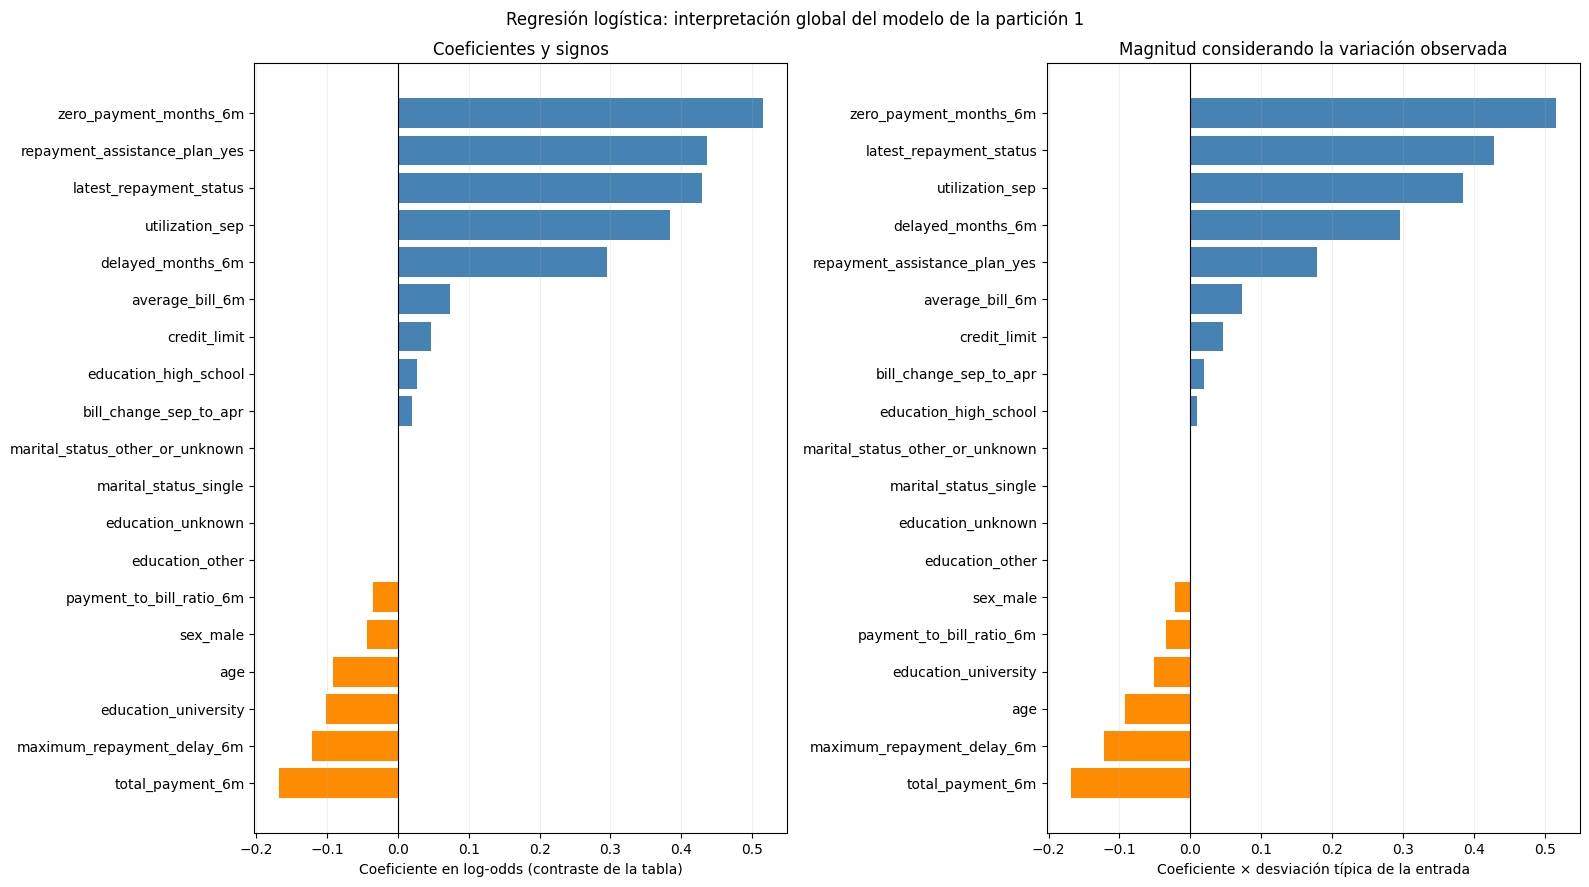

In [29]:
lr_signed_coefficients = pd.Series(
    lr_reference_model.coef_[0], index=lr_reference_names, name="Coeficiente"
)
lr_scaled_contributions = lr_signed_coefficients * lr_reference_transformed.std(ddof=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
for ax, values, title, xlabel in (
    (axes[0], lr_signed_coefficients, "Coeficientes y signos",
     "Coeficiente en log-odds (contraste de la tabla)"),
    (axes[1], lr_scaled_contributions, "Magnitud considerando la variación observada",
     "Coeficiente × desviación típica de la entrada"),
):
    ordered = values.sort_values()
    colors = ["steelblue" if value > 0 else "darkorange" if value < 0 else "gray" for value in ordered]
    ax.barh(ordered.index, ordered.values, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("Regresión logística: interpretación global del modelo de la partición 1")
plt.tight_layout()
plt.show()

La gráfica de coeficientes destaca los meses sin pago, el plan de asistencia, el estado reciente de pago, la utilización y los meses con retraso. Los pagos totales presentan la mayor magnitud negativa. Las cuatro entradas anuladas por L1 quedan en el eje de cero; sus categorías se conservaron en la codificación, pero este ajuste no les asignó un coeficiente distinto de cero.

Al incorporar la variación observada, `repayment_assistance_plan_yes` pasa de la segunda a la quinta posición entre las contribuciones positivas mostradas. Su coeficiente describe un cambio completo de categoría, mientras que su desviación típica binaria es menor que uno. Por eso su barra se reduce respecto a las numéricas ya estandarizadas. El cambio de orden ilustra que **magnitud del coeficiente y magnitud de la variación de su contribución no son lo mismo**. No se interpreta esta segunda gráfica como una clasificación definitiva de importancia.

### <a id="sec-7-7"></a> 7.7. Estabilidad entre las cinco particiones

Se alinean los coeficientes por sus nombres de entrada, sin sustituir por cero una columna que no haya sido generada. Antes de compararlos, se comprueba que las categorías de referencia coincidan. La tabla resume la media, la desviación típica, la presencia de coeficientes positivos, negativos o nulos y el número de modelos en los que existe cada entrada.

La gráfica muestra los cinco valores individuales junto con una caja que resume su dispersión. Con solo cinco modelos, las cajas no son intervalos de confianza ni permiten afirmar significación estadística. La variabilidad combina cambios en los datos de entrenamiento, en la regularización seleccionada y, para las numéricas, en la escala aprendida; **no es una estimación aislada del efecto del muestreo con una configuración fija**.

Se representa también el par `maximum_repayment_delay_6m` y `delayed_months_6m`, cuya correlación de Spearman fue 0,982. El objetivo es observar cómo se reparte su contribución entre los modelos y si cambia su signo, sin deducir que uno de ellos sea irrelevante o que la relación sea causal.

,Media,Desviación típica,Modelos con entrada,Coeficiente positivo,Coeficiente negativo,Coeficiente nulo
zero_payment_months_6m,0.5051,0.0095,5,5,0,0
repayment_assistance_plan_yes,0.4520,0.0262,5,5,0,0
latest_repayment_status,0.4151,0.0133,5,5,0,0
utilization_sep,0.3926,0.0120,5,5,0,0
delayed_months_6m,0.3114,0.0200,5,5,0,0
total_payment_6m,-0.1692,0.0089,5,0,5,0
maximum_repayment_delay_6m,-0.1269,0.0203,5,0,5,0
age,-0.1060,0.0158,5,0,5,0
marital_status_other_or_unknown,-0.0925,0.0959,5,0,3,2
education_other,-0.0669,0.0646,5,0,3,2


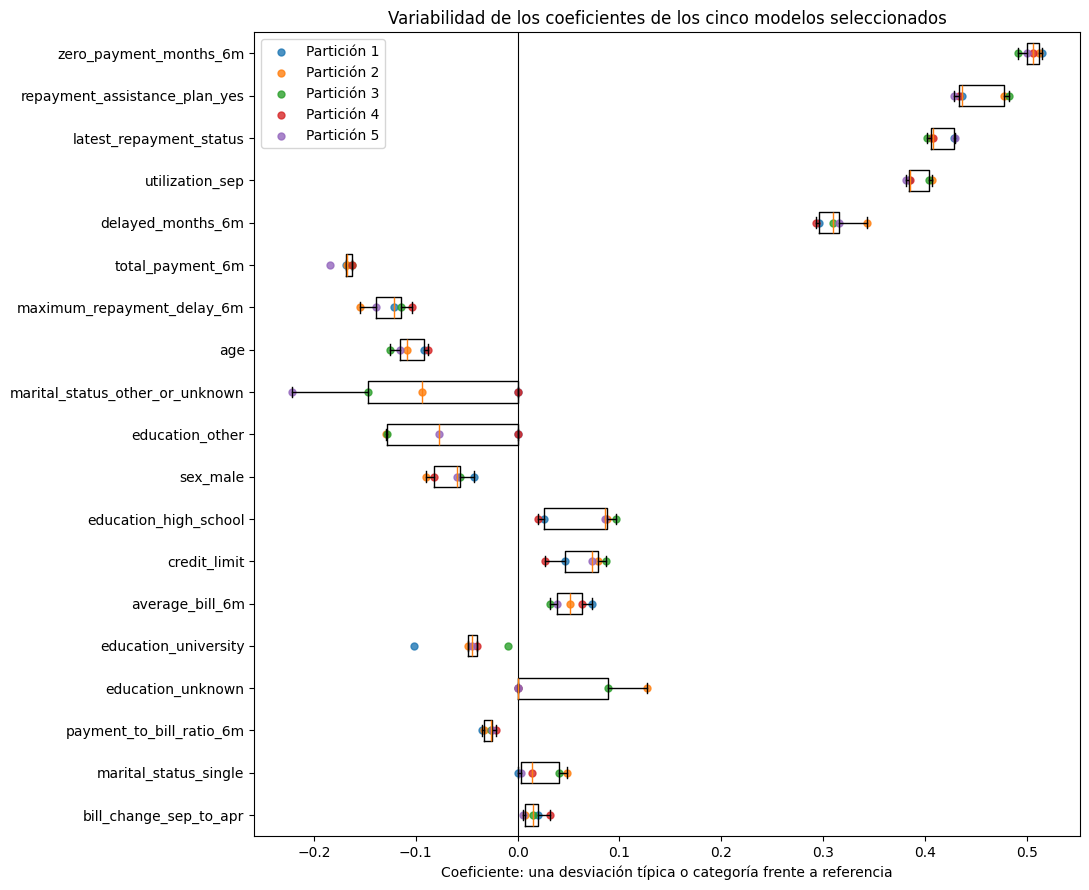

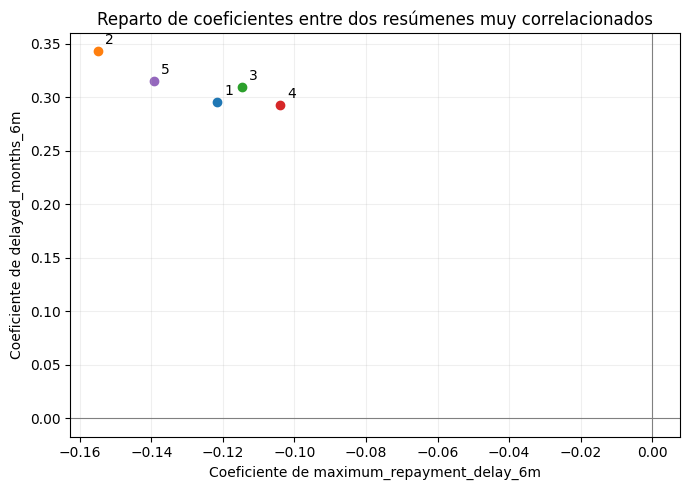

In [30]:
lr_coefficient_rows = []
lr_reference_rows = []
for fold, pipeline in enumerate(lr_models, start=1):
    names = pipeline["preprocess"].get_feature_names_out()
    lr_coefficient_rows.append(pd.Series(pipeline["model"].coef_[0], index=names, name=fold))
    encoder = pipeline["preprocess"].named_transformers_["categorical"].named_steps["encoder"]
    lr_reference_rows.append({
        variable: categories[drop_idx]
        for variable, categories, drop_idx in zip(
            categorical_features, encoder.categories_, encoder.drop_idx_
        )
    })

lr_references_by_fold = pd.DataFrame(lr_reference_rows, index=range(1, N_SPLITS + 1))
if (lr_references_by_fold.nunique(dropna=False) > 1).any():
    raise ValueError("Las referencias cambian entre modelos; hay que alinear sus contrastes antes de compararlos.")
lr_coefficients_by_fold = pd.DataFrame(lr_coefficient_rows)
lr_coefficients_by_fold.index.name = "Partición"
lr_coefficient_stability = pd.DataFrame({
    "Media": lr_coefficients_by_fold.mean(),
    "Desviación típica": lr_coefficients_by_fold.std(ddof=1),
    "Modelos con entrada": lr_coefficients_by_fold.notna().sum(),
    "Coeficiente positivo": (lr_coefficients_by_fold > 0).sum(),
    "Coeficiente negativo": (lr_coefficients_by_fold < 0).sum(),
    "Coeficiente nulo": (lr_coefficients_by_fold == 0).sum(),
})
lr_coefficient_stability = lr_coefficient_stability.loc[
    lr_coefficient_stability["Media"].abs().sort_values(ascending=False).index
]
display(lr_coefficient_stability.round(4))

plot_columns = lr_coefficient_stability.index[::-1]
fig, ax = plt.subplots(figsize=(11, 9))
positions = np.arange(1, len(plot_columns) + 1)
ax.boxplot(
    [lr_coefficients_by_fold[column].dropna().to_numpy() for column in plot_columns],
    vert=False, positions=positions, showfliers=False,
)
for fold in lr_coefficients_by_fold.index:
    ax.scatter(lr_coefficients_by_fold.loc[fold, plot_columns], positions,
               s=25, alpha=0.8, label=f"Partición {fold}")
ax.set_yticks(positions, labels=plot_columns)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Variabilidad de los coeficientes de los cinco modelos seleccionados",
       xlabel="Coeficiente: una desviación típica o categoría frente a referencia")
ax.legend()
plt.tight_layout()
plt.show()

first_variable = "maximum_repayment_delay_6m"
second_variable = "delayed_months_6m"
fig, ax = plt.subplots(figsize=(7, 5))
for fold in lr_coefficients_by_fold.index:
    x_value = lr_coefficients_by_fold.loc[fold, first_variable]
    y_value = lr_coefficients_by_fold.loc[fold, second_variable]
    ax.scatter(x_value, y_value)
    ax.annotate(str(fold), (x_value, y_value), xytext=(5, 5), textcoords="offset points")
ax.axvline(0, color="gray", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(xlabel=f"Coeficiente de {first_variable}", ylabel=f"Coeficiente de {second_variable}",
       title="Reparto de coeficientes entre dos resúmenes muy correlacionados")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Las 19 entradas están presentes en los cinco modelos y las referencias categóricas coinciden, por lo que los contrastes se pueden alinear. **No se observan inversiones entre signo positivo y negativo**: las entradas activas conservan su dirección, aunque algunas alternan entre un coeficiente nulo y uno no nulo.

Los principales coeficientes positivos muestran poca dispersión en términos absolutos: `zero_payment_months_6m` tiene media 0,5051 y desviación típica 0,0095; `latest_repayment_status`, 0,4151 y 0,0133; y `utilization_sep`, 0,3926 y 0,0120. El plan de asistencia es positivo en los cinco modelos (media 0,4520; desviación 0,0262). `total_payment_6m` mantiene un coeficiente negativo (media −0,1692; desviación 0,0089). Su repetición en estos entrenamientos respalda la consistencia descriptiva de esas partes de la explicación, sin demostrar que sean correctas para otra población.

Las categorías menos frecuentes presentan mayor incertidumbre descriptiva sobre su activación y magnitud. `education_unknown` queda anulada en tres modelos y es positiva en dos; `education_other` y `marital_status_other_or_unknown` son nulas en dos y negativas en tres. Esta última tiene media −0,0925 y desviación típica 0,0959. `marital_status_single` se anula en uno y es positiva en cuatro. Una explicación basada solo en los ceros de la partición 1 ocultaría esas diferencias.

En el gráfico del par correlacionado, **el retraso máximo es negativo y el número de meses con retraso es positivo en las cinco particiones**. El modelo 2 presenta el coeficiente más negativo del primero y el más positivo del segundo. Este reparto muestra por qué conviene interpretar conjuntamente ambos resúmenes: sus coeficientes no equivalen a efectos independientes sobre el riesgo. Con cinco ajustes y configuraciones distintas, el gráfico no identifica el mecanismo que produce ese reparto ni demuestra una relación general entre sus coeficientes.

### <a id="sec-7-8"></a> 7.8. Visualización con InterpretML

Se reproduce el modelo de la partición 1 con el envoltorio de InterpretML, usando **los mismos parámetros, datos de entrenamiento y entradas ya transformadas**. No se vuelve a ajustar el preprocesamiento ni se realiza otra búsqueda. Esta celda añade un único ajuste para generar la visualización, y comprueba que los coeficientes y las probabilidades coincidan con el modelo que se está explicando.

La vista global permite seleccionar una entrada y explorar su contribución a los log-odds. Las variables numéricas se muestran en su escala estandarizada; las one-hot toman valores 0 y 1. Las líneas dibujadas entre esos valores no representan categorías intermedias reales. La visualización no muestra efectos causales ni curvas de probabilidad independientes del resto de las variables.

La interpretación local comparada se desarrollará en el apartado 10, utilizando los mismos casos para las tres familias y al menos uno de cada clase. El entrenamiento final con todos los datos etiquetados permanece en el apartado 12.

In [31]:
from interpret.glassbox import LogisticRegression as ExplainableLogisticRegression

lr_explainer = ExplainableLogisticRegression(
    feature_names=list(lr_reference_names),
    feature_types=["continuous"] * len(lr_reference_names),
    **lr_reference_model.get_params(),
)
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    lr_explainer.fit(lr_reference_transformed, y.iloc[lr_reference_train_idx])

lr_explanation_input = lr_reference_preprocessor.transform(X_raw.iloc[lr_reference_valid_idx])
if not np.allclose(lr_explainer._model().coef_, lr_reference_model.coef_, rtol=1e-6, atol=1e-8):
    raise ValueError("Los coeficientes de InterpretML no coinciden con los del modelo explicado.")
if not np.allclose(
    lr_explainer.predict_proba(lr_explanation_input),
    lr_reference_pipeline.predict_proba(X_raw.iloc[lr_reference_valid_idx]),
    rtol=1e-6, atol=1e-8,
):
    raise ValueError("Las probabilidades de InterpretML no coinciden con las del modelo explicado.")
print("Coeficientes y probabilidades coinciden con el modelo de la partición 1.")
lr_global_explanation = lr_explainer.explain_global(name="Regresión logística: partición 1")
show(lr_global_explanation)

Coeficientes y probabilidades coinciden con el modelo de la partición 1.


La comprobación confirma que los coeficientes y las probabilidades de la reproducción en InterpretML coinciden con los del modelo de la partición 1. Por tanto, la vista global explica ese mismo ajuste, no un modelo alternativo con otras predicciones. La visualización aporta una forma de explorar sus contribuciones; no añade una evaluación independiente ni transforma sus asociaciones en efectos causales.

### <a id="sec-7-9"></a> 7.9. Síntesis de la interpretación y limitaciones

La regresión logística ofrece una explicación global compacta mediante coeficientes y contrastes explícitos. En los cinco entrenamientos destacan asociaciones positivas consistentes para los meses sin pago, el estado reciente de pago, la utilización, los meses con retraso y el plan de asistencia; los pagos totales mantienen una asociación negativa. Los signos activos son estables en estos ajustes, pero la magnitud y la selección de algunas categorías varían.

La inspección revela límites que las métricas predictivas por sí solas no muestran. El coeficiente negativo del retraso máximo debe leerse junto al número de meses con retraso, fuertemente correlacionado con él. El plan de asistencia conserva una asociación positiva que no justifica afirmar que cause perjuicio. Los códigos de estado de pago tienen documentación incompleta para valores no positivos y su tratamiento numérico impone una relación lineal en los log-odds. Las categorías poco frecuentes y la regularización dificultan atribuir un significado general a coeficientes pequeños o anulados.

L1 reduce la representación de la partición 1 a 15 coeficientes activos de 19, pero otros entrenamientos conservan hasta los 19. La explicabilidad permite reconocer estos patrones y cuestionar lecturas engañosas; no garantiza causalidad, equidad ni validez fuera del conjunto semisintético. Los cinco entrenamientos se solapan y utilizan regularizaciones seleccionadas por separado, por lo que su variabilidad no constituye un intervalo de confianza ni una prueba de estabilidad poblacional.

La interpretación global de esta familia queda documentada. Las explicaciones locales comparadas se completarán en el apartado 10 con casos comunes a los tres modelos. La elección de la familia y el entrenamiento final siguen pendientes de la comparación del proyecto.

[Volver al índice](#indice)

## <a id="sec-8"></a> 8. Explainable Boosting Machine

### <a id="sec-8-1"></a> 8.1. Modelo aditivo y explicabilidad

Explainable Boosting Machine (EBM) es un modelo aditivo generalizado que aprende una función para cada variable mediante boosting de árboles pequeños y combina varias réplicas del entrenamiento (*bags*). Para clasificación binaria, la predicción tiene la forma:

$$
\log\left(\frac{p}{1-p}\right)=\beta_0+\sum_{j=1}^{15}f_j(x_j),
\qquad p=P(Y=1\mid X).
$$

Se fija **`interactions=0`**, de modo que cada término corresponde a una sola variable original. El modelo puede aprender umbrales, mesetas y relaciones no monótonas, pero no añade funciones conjuntas entre variables. Los resúmenes y cocientes que ya existen en los datos mantienen sus definiciones.

La explicación global consiste en inspeccionar las funciones $f_j$: una contribución positiva aumenta el logit respecto al intercepto y una negativa lo reduce. La probabilidad resulta de aplicar la función logística a la suma completa; una función aislada no es una curva independiente de probabilidad. La correlación entre predictores puede influir en cómo se reparte la contribución, y las funciones no identifican efectos causales.

Se utilizan los 15 predictores originales, sin escalado ni one-hot, mediante el pipeline del apartado 5. Las categóricas se declaran nominales y las numéricas continuas; estas últimas se discretizan internamente, incluidos los recuentos y el código de estado de pago. No se inventan significados para sus códigos no positivos, ni se fuerzan formas monótonas a partir de intuiciones no verificadas.

### <a id="sec-8-2"></a> 8.2. Configuraciones y control del coste

La búsqueda compara cuatro configuraciones:

| Parámetro | Valores | Justificación |
| --- | --- | --- |
| `max_bins` | 16 y 32 | Comparar funciones con una discretización más gruesa o más detallada. Es un máximo de intervalos/categorías, no el número garantizado de intervalos utilizados. |
| `min_samples_leaf` | 10 y 50 | Comparar mínimos de registros por hoja de los árboles usados en boosting. No es un mínimo garantizado de observaciones en cada intervalo final. |

Se mantienen `max_leaves=2`, `learning_rate=0.05`, un máximo de 2.000 rondas y cuatro réplicas externas de bagging. `greedy_ratio=0` y `cyclic_progress=True` utilizan actualizaciones cíclicas por términos. Estas elecciones acotan el coste y facilitan una primera representación aditiva; la búsqueda no demuestra que sean globalmente óptimas.

La parada temprana usa `validation_size=0.15` y `early_stopping_rounds=50`. Esa reserva se crea **dentro de los datos que recibe cada ajuste**, sin consultar la validación interna de selección ni la externa de evaluación. Es distinta de las cinco particiones internas definidas en el apartado 4 y su reparto es gestionado por EBM; no se afirma que mantenga agrupados los perfiles idénticos. Los grupos sí se mantienen separados en las particiones internas y externas usadas para seleccionar y evaluar.

Se selecciona la mayor media de ROC-AUC interna. En caso de empate exacto, se prefiere `max_bins` menor y después `min_samples_leaf` mayor. El umbral utiliza la misma rejilla y criterio de exactitud equilibrada que la regresión logística.

Se requieren las funciones `metric_scores` y `choose_threshold` del apartado 7.2. Si se conserva el kernel de las ejecuciones anteriores, ya estarán disponibles; no es necesario repetir el entrenamiento de regresión logística.

In [32]:
from time import perf_counter
from scipy.special import expit
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, ParameterGrid, cross_val_predict

EBM_FIXED_PARAMS = {
    "feature_types": [
        "nominal" if column in categorical_features else "continuous"
        for column in feature_columns
    ],
    "interactions": 0,
    "max_leaves": 2,
    "learning_rate": 0.05,
    "greedy_ratio": 0,
    "cyclic_progress": True,
    "max_rounds": 2000,
    "outer_bags": 4,
    "validation_size": 0.15,
    "early_stopping_rounds": 50,
}
EBM_PARAM_GRID = {
    "model__max_bins": [16, 32],
    "model__min_samples_leaf": [10, 50],
}
ebm_base_pipeline = make_ebm_pipeline(**EBM_FIXED_PARAMS)
display(pd.DataFrame(list(ParameterGrid(EBM_PARAM_GRID))).rename(columns={
    "model__max_bins": "Máximo de bins", "model__min_samples_leaf": "Mínimo por hoja"
}))
print("Configuraciones por búsqueda interna:", len(list(ParameterGrid(EBM_PARAM_GRID))))
print("Interacciones:", ebm_base_pipeline["model"].interactions)

,Máximo de bins,Mínimo por hoja
0,16,10
1,16,50
2,32,10
3,32,50


Configuraciones por búsqueda interna: 4
Interacciones: 0


### <a id="sec-8-3"></a> 8.3. Evaluación anidada de cinco particiones

Se reutilizan exactamente las particiones externas y las reglas de selección de la regresión logística. En cada entrenamiento externo, cinco particiones internas comparan las cuatro configuraciones. La elegida genera probabilidades OOF internas para ajustar el umbral y se reentrena con todo ese entrenamiento externo antes de predecir su validación.

Se realizan **130 ajustes de EBM**: por cada partición externa, 20 de búsqueda, 5 de probabilidades internas OOF y 1 del modelo externo. Cada ajuste incluye cuatro réplicas de bagging y puede requerir numerosas rondas; su coste es mayor que el de un ajuste de regresión logística. La celda anuncia cada búsqueda y muestra el tiempo al terminar la partición, sin cambiar el paralelismo reproducible establecido en el apartado 1.

Se guardan modelos, búsquedas, tablas de umbrales y predicciones externas OOF. Se comprueba además que no se hayan aprendido términos de interacción. La ROC-AUC sobre el entrenamiento se conserva solo como diagnóstico del ajuste; no se utiliza para seleccionar ni como estimación de generalización.

In [33]:
ebm_models = []
ebm_search_results = []
ebm_threshold_tables = []
ebm_settings_rows = []
ebm_default_rows = []
ebm_tuned_rows = []
ebm_oof_probability = np.full(len(y), np.nan)
ebm_oof_threshold = np.full(len(y), np.nan)
ebm_oof_fold = np.zeros(len(y), dtype=int)

for fold, (outer_train_idx, outer_valid_idx) in enumerate(cv_splits, start=1):
    fold_start = perf_counter()
    print(f"Partición EBM {fold}/{N_SPLITS}: comienza la búsqueda interna (20 ajustes).", flush=True)
    inner_X = X_raw.iloc[outer_train_idx]
    inner_y = y.iloc[outer_train_idx]
    inner_splits = make_inner_splits(outer_train_idx)
    search = GridSearchCV(
        clone(ebm_base_pipeline), EBM_PARAM_GRID, cv=inner_splits,
        scoring=SCORING, refit=False, n_jobs=N_JOBS, error_score="raise",
    )
    search.fit(inner_X, inner_y)
    search_table = pd.DataFrame(search.cv_results_).sort_values(
        ["mean_test_roc_auc", "param_model__max_bins", "param_model__min_samples_leaf"],
        ascending=[False, True, False],
    )
    best_row = search_table.iloc[0]
    best_params = best_row["params"]
    selected_pipeline = clone(ebm_base_pipeline).set_params(**best_params)
    print(f"Partición {fold}: búsqueda terminada; generación de probabilidades OOF internas.", flush=True)
    inner_probability = cross_val_predict(
        selected_pipeline, inner_X, inner_y, cv=inner_splits,
        method="predict_proba", n_jobs=N_JOBS,
    )[:, 1]
    threshold, threshold_table = choose_threshold(inner_y, inner_probability, inner_splits)
    selected_pipeline.fit(inner_X, inner_y)
    model = selected_pipeline["model"]
    if not np.array_equal(model.classes_, [0, 1]):
        raise ValueError("El orden de clases esperado es [0, 1].")
    if model.interactions != 0 or any(len(term) != 1 for term in model.term_features_):
        raise ValueError("Se esperaba un EBM aditivo sin términos de interacción.")
    outer_probability = selected_pipeline.predict_proba(X_raw.iloc[outer_valid_idx])[:, 1]
    outer_y = y.iloc[outer_valid_idx]
    ebm_default_rows.append(metric_scores(outer_y, outer_probability, DEFAULT_THRESHOLD))
    ebm_tuned_rows.append(metric_scores(outer_y, outer_probability, threshold))
    ebm_oof_probability[outer_valid_idx] = outer_probability
    ebm_oof_threshold[outer_valid_idx] = threshold
    ebm_oof_fold[outer_valid_idx] = fold
    ebm_settings_rows.append({
        "Partición": fold,
        "max_bins": best_params["model__max_bins"],
        "min_samples_leaf": best_params["model__min_samples_leaf"],
        "ROC-AUC interna": best_row["mean_test_roc_auc"],
        "ROC-AUC entrenamiento": roc_auc_score(inner_y, selected_pipeline.predict_proba(inner_X)[:, 1]),
        "ROC-AUC externa": roc_auc_score(outer_y, outer_probability),
        "Umbral": threshold,
        "Términos univariantes": len(model.term_features_),
    })
    ebm_models.append(selected_pipeline)
    ebm_search_results.append(search_table)
    ebm_threshold_tables.append(threshold_table)
    print(f"Partición {fold}/{N_SPLITS} completada en {(perf_counter() - fold_start) / 60:.1f} min: "
          f"max_bins={best_params['model__max_bins']}, "
          f"min_samples_leaf={best_params['model__min_samples_leaf']}, "
          f"umbral={threshold:.2f}", flush=True)

if not np.isfinite(ebm_oof_probability).all() or not np.all(ebm_oof_fold > 0):
    raise ValueError("Faltan predicciones externas OOF de EBM.")
ebm_fold_settings = pd.DataFrame(ebm_settings_rows).set_index("Partición")
ebm_scores_default = pd.DataFrame(ebm_default_rows, index=ebm_fold_settings.index)
ebm_scores_tuned = pd.DataFrame(ebm_tuned_rows, index=ebm_fold_settings.index)
ebm_oof_results = pd.DataFrame({
    ID_COLUMN: train_raw[ID_COLUMN],
    "true_class": y,
    "fold": ebm_oof_fold,
    "probability_class_1": ebm_oof_probability,
    "threshold": ebm_oof_threshold,
    "prediction_default": (ebm_oof_probability >= DEFAULT_THRESHOLD).astype(int),
    "prediction_tuned": (ebm_oof_probability >= ebm_oof_threshold).astype(int),
}, index=X_raw.index)
display(ebm_fold_settings.round(4))

Partición EBM 1/5: comienza la búsqueda interna (20 ajustes).
Partición 1: búsqueda terminada; generación de probabilidades OOF internas.
Partición 1/5 completada en 0.4 min: max_bins=32, min_samples_leaf=10, umbral=0.20
Partición EBM 2/5: comienza la búsqueda interna (20 ajustes).
Partición 2: búsqueda terminada; generación de probabilidades OOF internas.
Partición 2/5 completada en 0.5 min: max_bins=32, min_samples_leaf=10, umbral=0.20
Partición EBM 3/5: comienza la búsqueda interna (20 ajustes).
Partición 3: búsqueda terminada; generación de probabilidades OOF internas.
Partición 3/5 completada en 0.4 min: max_bins=32, min_samples_leaf=10, umbral=0.20
Partición EBM 4/5: comienza la búsqueda interna (20 ajustes).
Partición 4: búsqueda terminada; generación de probabilidades OOF internas.
Partición 4/5 completada en 0.3 min: max_bins=32, min_samples_leaf=10, umbral=0.25
Partición EBM 5/5: comienza la búsqueda interna (20 ajustes).
Partición 5: búsqueda terminada; generación de probabi

,max_bins,min_samples_leaf,ROC-AUC interna,ROC-AUC entrenamiento,ROC-AUC externa,Umbral,Términos univariantes
Partición,,,,,,,
1,32,10,0.7757,0.7821,0.7715,0.20,15
2,32,10,0.7775,0.7851,0.7641,0.20,15
3,32,10,0.7731,0.7796,0.7810,0.20,15
4,32,10,0.7739,0.7796,0.7781,0.25,15
5,32,50,0.7726,0.7787,0.7827,0.25,15


Las cinco búsquedas seleccionan **`max_bins=32`**. Cuatro eligen `min_samples_leaf=10` y una, la partición 5, elige 50. Esto sugiere que la discretización más detallada de las dos opciones obtiene la mejor ROC-AUC interna en estos entrenamientos; no demuestra que aumentar los bins más allá de 32 mejore el resultado. Se mantiene la rejilla previamente definida y se señala que su máximo se selecciona en todas las particiones.

Los cinco modelos contienen **15 términos univariantes, sin interacciones**. Los umbrales elegidos son 0,20 en tres particiones y 0,25 en dos, siempre mediante la validación interna. La ROC-AUC de entrenamiento varía entre 0,7787 y 0,7851 y la externa entre 0,7641 y 0,7827. La mayor diferencia entrenamiento–validación es aproximadamente 0,021 en la partición 2; en las particiones 3 y 5 la externa es ligeramente superior. Estas diferencias son diagnósticos de muestras distintas y no constituyen una prueba de ausencia de sobreajuste.

### <a id="sec-8-4"></a> 8.4. Resultados externos y efecto del umbral

Se registran las seis métricas de cada partición con umbral 0,5 y con el umbral ajustado internamente. Las medias y desviaciones típicas se calculan igual que en las familias anteriores y se comparan con la referencia mayoritaria. La comparación conjunta con regresión logística y el modelo lógico se realizará en el apartado 9.

Cambiar el umbral no modifica ROC-AUC. Se examina si la mejora de exactitud equilibrada interna se reproduce fuera de ese entrenamiento y qué ocurre con sensibilidad, precisión y exactitud. No se describirá un aumento de detección como una mejora general si aumenta también el número de falsos positivos.

In [34]:
print("Resultados externos de EBM con umbral 0,5:")
display(ebm_scores_default.round(4))
print("Resultados externos de EBM con umbral interno ajustado:")
display(ebm_scores_tuned.round(4))

ebm_summary_default = pd.DataFrame({
    "Media": ebm_scores_default.mean(),
    "Desviación típica": ebm_scores_default.std(ddof=1),
})
ebm_summary_tuned = pd.DataFrame({
    "Media": ebm_scores_tuned.mean(),
    "Desviación típica": ebm_scores_tuned.std(ddof=1),
})
ebm_comparison = pd.concat({
    "Referencia mayoritaria": baseline_summary,
    "EBM: umbral 0,5": ebm_summary_default,
    "EBM: umbral ajustado": ebm_summary_tuned,
}, axis=1)
display(ebm_comparison.round(4))
print("Cambio de métricas externas al ajustar el umbral (ajustado − 0,5):")
display((ebm_scores_tuned - ebm_scores_default).round(4))

Resultados externos de EBM con umbral 0,5:


,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.7715,0.8080,0.6223,0.2920,0.6337,0.3998
2,0.7641,0.8077,0.6188,0.2869,0.6155,0.3914
3,0.7810,0.8233,0.6359,0.3113,0.6784,0.4267
4,0.7781,0.8252,0.6342,0.3088,0.6660,0.4220
5,0.7827,0.8247,0.6285,0.2923,0.6847,0.4097


Resultados externos de EBM con umbral interno ajustado:


,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.7715,0.7060,0.6949,0.6752,0.3989,0.5015
2,0.7641,0.7036,0.6909,0.6685,0.3905,0.4930
3,0.7810,0.7129,0.7055,0.6925,0.3972,0.5048
4,0.7781,0.7764,0.7033,0.5789,0.4668,0.5169
5,0.7827,0.7721,0.7041,0.5875,0.4625,0.5176


Referencia mayoritaria                   EBM: umbral 0,5  \
                                   Media Desviación típica           Media   
roc_auc                           0.5000            0.0000          0.7755   
accuracy                          0.7879            0.0052          0.8178   
balanced_accuracy                 0.5000            0.0000          0.6279   
recall                            0.0000            0.0000          0.2983   
precision                         0.0000            0.0000          0.6556   
f1                                0.0000            0.0000          0.4099   

                                    EBM: umbral ajustado                    
                  Desviación típica                Media Desviación típica  
roc_auc                      0.0077               0.7755            0.0077  
accuracy                     0.0091               0.7342            0.0367  
balanced_accuracy            0.0074               0.6997            0.0064  
recall                       0.0110               0.6405            0.0531  
precision                    0.0298               0.4232            0.0380  
f1                           0.0148               0.5068            0.0105

Cambio de métricas externas al ajustar el umbral (ajustado − 0,5):


,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.0,-0.1019,0.0726,0.3832,-0.2347,0.1018
2,0.0,-0.1041,0.0721,0.3816,-0.2251,0.1016
3,0.0,-0.1104,0.0696,0.3813,-0.2812,0.0781
4,0.0,-0.0488,0.0691,0.2701,-0.1991,0.0949
5,0.0,-0.0526,0.0756,0.2952,-0.2222,0.1079


EBM alcanza una **ROC-AUC externa media de 0,7755, con desviación típica de 0,0077**, frente a 0,5 de la referencia mayoritaria. Esta medida muestra discriminación, pero no certifica calibración ni validez fuera del conjunto analizado.

Con umbral **0,5**, la exactitud media es **81,78 %**, la exactitud equilibrada 62,79 %, la sensibilidad 29,83 %, la precisión 65,56 % y F1 0,4099. Se supera la exactitud mayoritaria del 78,79 %, pero todavía quedan sin detectar aproximadamente siete de cada diez casos positivos.

Con los umbrales internos ajustados, la exactitud equilibrada sube al **69,97 %**, la sensibilidad al **64,05 %** y F1 a **0,5068**. Las tres métricas mejoran en las cinco validaciones externas. La contrapartida es una precisión del **42,32 %** y una exactitud del **73,42 %**, inferior a la obtenida con 0,5 y a la referencia mayoritaria. ROC-AUC permanece igual, porque las probabilidades no cambian.

La mejora media de exactitud equilibrada es de aproximadamente **7,18 puntos porcentuales**, mientras que la exactitud disminuye **8,36 puntos**. Por tanto, el ajuste favorece la detección a costa de más falsos positivos; no es una mejora uniforme. Se conservan ambas versiones y no se elige un nuevo umbral usando las etiquetas externas.

### <a id="sec-8-5"></a> 8.5. Primera exploración de las funciones aprendidas

Se utiliza el modelo del **entrenamiento externo de la partición 1**, como ejemplo fijado por su posición, no por su rendimiento. La vista `Summary` ordena las variables por la media ponderada del valor absoluto de sus contribuciones (*Mean Absolute Score*). Esta medida describe cuánto varían sus contribuciones en los datos de entrenamiento; no indica dirección, causalidad ni importancia predictiva independiente de las otras entradas.

Al seleccionar una variable se observa su función en **log-odds** y su distribución. Las numéricas se conservan en sus unidades originales; las categóricas se muestran como niveles nominales. Las funciones pueden contener saltos por la discretización. Las bandas mostradas reflejan variabilidad de las réplicas de bagging, no intervalos de confianza causales o garantías de generalización.

El intercepto se muestra por separado. Su transformación logística es la probabilidad de un caso hipotético cuya suma de contribuciones sea cero; no se identifica automáticamente con la prevalencia positiva del conjunto. No se modifican ni monotonizan las funciones, pues una edición cambiaría el modelo cuyo rendimiento acabamos de evaluar.

Esta primera vista permitirá identificar las funciones que convenga analizar con más detalle tras revisar las salidas. La interpretación local comparada se mantiene en el apartado 10.

In [35]:
EBM_REFERENCE_FOLD = 1
ebm_reference_pipeline = ebm_models[EBM_REFERENCE_FOLD - 1]
ebm_reference_model = ebm_reference_pipeline["model"]

ebm_global_importance = pd.DataFrame({
    "Variable": ebm_reference_model.term_names_,
    "Media del valor absoluto de la contribución": ebm_reference_model.term_importances(),
}).sort_values("Media del valor absoluto de la contribución", ascending=False)
display(ebm_global_importance.round(4))
print("Tipos de variables aprendidos:", dict(zip(
    ebm_reference_model.feature_names_in_, ebm_reference_model.feature_types_in_
)))
ebm_reference_intercept = float(ebm_reference_model.intercept_[0])
print(f"Intercepto (log-odds): {ebm_reference_intercept:.4f}")
print(f"Probabilidad con suma de contribuciones cero: {expit(ebm_reference_intercept):.2%}")
ebm_global_explanation = ebm_reference_model.explain_global(name="EBM aditivo: partición 1")
show(ebm_global_explanation)

,Variable,Media del valor absoluto de la contribución
11,payment_to_bill_ratio_6m,0.3158
5,latest_repayment_status,0.2445
12,zero_payment_months_6m,0.2134
7,delayed_months_6m,0.1830
14,repayment_assistance_plan,0.1632
4,age,0.1500
13,utilization_sep,0.1349
9,bill_change_sep_to_apr,0.0871
10,total_payment_6m,0.0760
0,credit_limit,0.0607


Tipos de variables aprendidos: {'credit_limit': 'continuous', 'sex': 'nominal', 'education': 'nominal', 'marital_status': 'nominal', 'age': 'continuous', 'latest_repayment_status': 'continuous', 'maximum_repayment_delay_6m': 'continuous', 'delayed_months_6m': 'continuous', 'average_bill_6m': 'continuous', 'bill_change_sep_to_apr': 'continuous', 'total_payment_6m': 'continuous', 'payment_to_bill_ratio_6m': 'continuous', 'zero_payment_months_6m': 'continuous', 'utilization_sep': 'continuous', 'repayment_assistance_plan': 'nominal'}
Intercepto (log-odds): -1.6001
Probabilidad con suma de contribuciones cero: 16.80%


La mayor media absoluta de contribución corresponde a **`payment_to_bill_ratio_6m` (0,3158)**, seguida de `latest_repayment_status` (0,2445), `zero_payment_months_6m` (0,2134), `delayed_months_6m` (0,1830) y el plan de asistencia (0,1632). Esta ordenación no contiene el signo de las funciones. Tampoco es directamente comparable con las magnitudes de coeficientes de regresión logística, que describen otros contrastes y otra representación.

Las funciones almacenadas en la vista global permiten observar:

- **Cociente entre pagos y facturas:** la contribución es positiva para cocientes pequeños, se vuelve negativa en valores intermedios y vuelve a ser positiva en la región alta. No se trata de una relación monótona; los valores altos pueden reflejar pagos extraordinarios o denominadores pequeños según el diccionario. La forma aprendida no demuestra que pagar más aumente causalmente la dificultad.
- **Estado reciente y meses con retraso:** la contribución crece en términos generales en los códigos positivos del estado reciente y al acumular meses con retraso, con saltos derivados de la discretización. No se asignan significados nuevos a los códigos negativos o cero.
- **Meses sin pago:** un mes sin pago tiene una contribución más negativa que cero meses, mientras que varios meses sin pago producen contribuciones crecientemente positivas. El modelo distingue casos que un único coeficiente lineal no puede representar con esa misma forma.
- **Edad:** la contribución es mayor en las edades más jóvenes, disminuye durante parte de la edad adulta y vuelve a aumentar en el tramo superior. Las edades extremas contienen menos registros, por lo que esa forma necesita una lectura cautelosa; no se identifica su mecanismo causal.
- **Plan de asistencia:** `no` tiene una contribución cercana a −0,103 y `yes` a 0,387. El contraste entre ambos términos es aproximadamente 0,491 log-odds. Esto describe la asociación aprendida y no demuestra perjuicio causado por el plan.

El retraso máximo presenta una función no monótona y contribución positiva para algunos retrasos elevados, aunque su coeficiente logístico fue negativo. Son explicaciones de modelos y representaciones diferentes, condicionadas por la información compartida con los demás resúmenes; la discrepancia no identifica cuál representa un efecto causal.

`sex` (0,0089) y `marital_status` (0,0135) tienen menor media absoluta de contribución. Eso no demuestra equidad ni ausencia de asociaciones. La probabilidad correspondiente al intercepto de −1,6001 es **16,80 %** cuando la suma de contribuciones es cero, no la prevalencia del conjunto. Las siguientes gráficas facilitarán inspeccionar estas formas y su variación entre modelos.

Los resultados mantienen el requisito de aditividad y muestran el intercambio entre detección y aciertos totales al ajustar el umbral. La explicación global revela relaciones no lineales y no monótonas que requieren examinar sus funciones, no solo una clasificación de importancia. Las siguientes comprobaciones utilizan los cinco modelos ya guardados; no vuelven a entrenarlos ni seleccionan una configuración final.

### <a id="sec-8-6"></a> 8.6. Gráficas de todas las funciones univariantes

Se representan las once funciones numéricas y las cuatro categóricas del modelo de la partición 1. Todas utilizan la misma escala vertical en log-odds para facilitar su comparación. Las numéricas se muestran como funciones escalonadas; los niveles nominales como puntos con sus bandas de variación entre réplicas.

Los intervalos pueden tener anchos muy diferentes y contener cantidades distintas de registros. La vista interactiva anterior incluye sus distribuciones y permite ampliar detalles: las colas de importes monetarios pueden comprimir visualmente los cambios situados en valores habituales. Los valores intermedios de recuentos y códigos no representan necesariamente valores observables, aunque se dibujen los límites de los intervalos.

Las bandas son las mismas medidas de variación del modelo que ofrece InterpretML; no son pruebas de significación. No se muestran bins especiales de ausentes que la explicación global omita, y no se extrapola la lectura de un intervalo extremo a una tendencia continua.

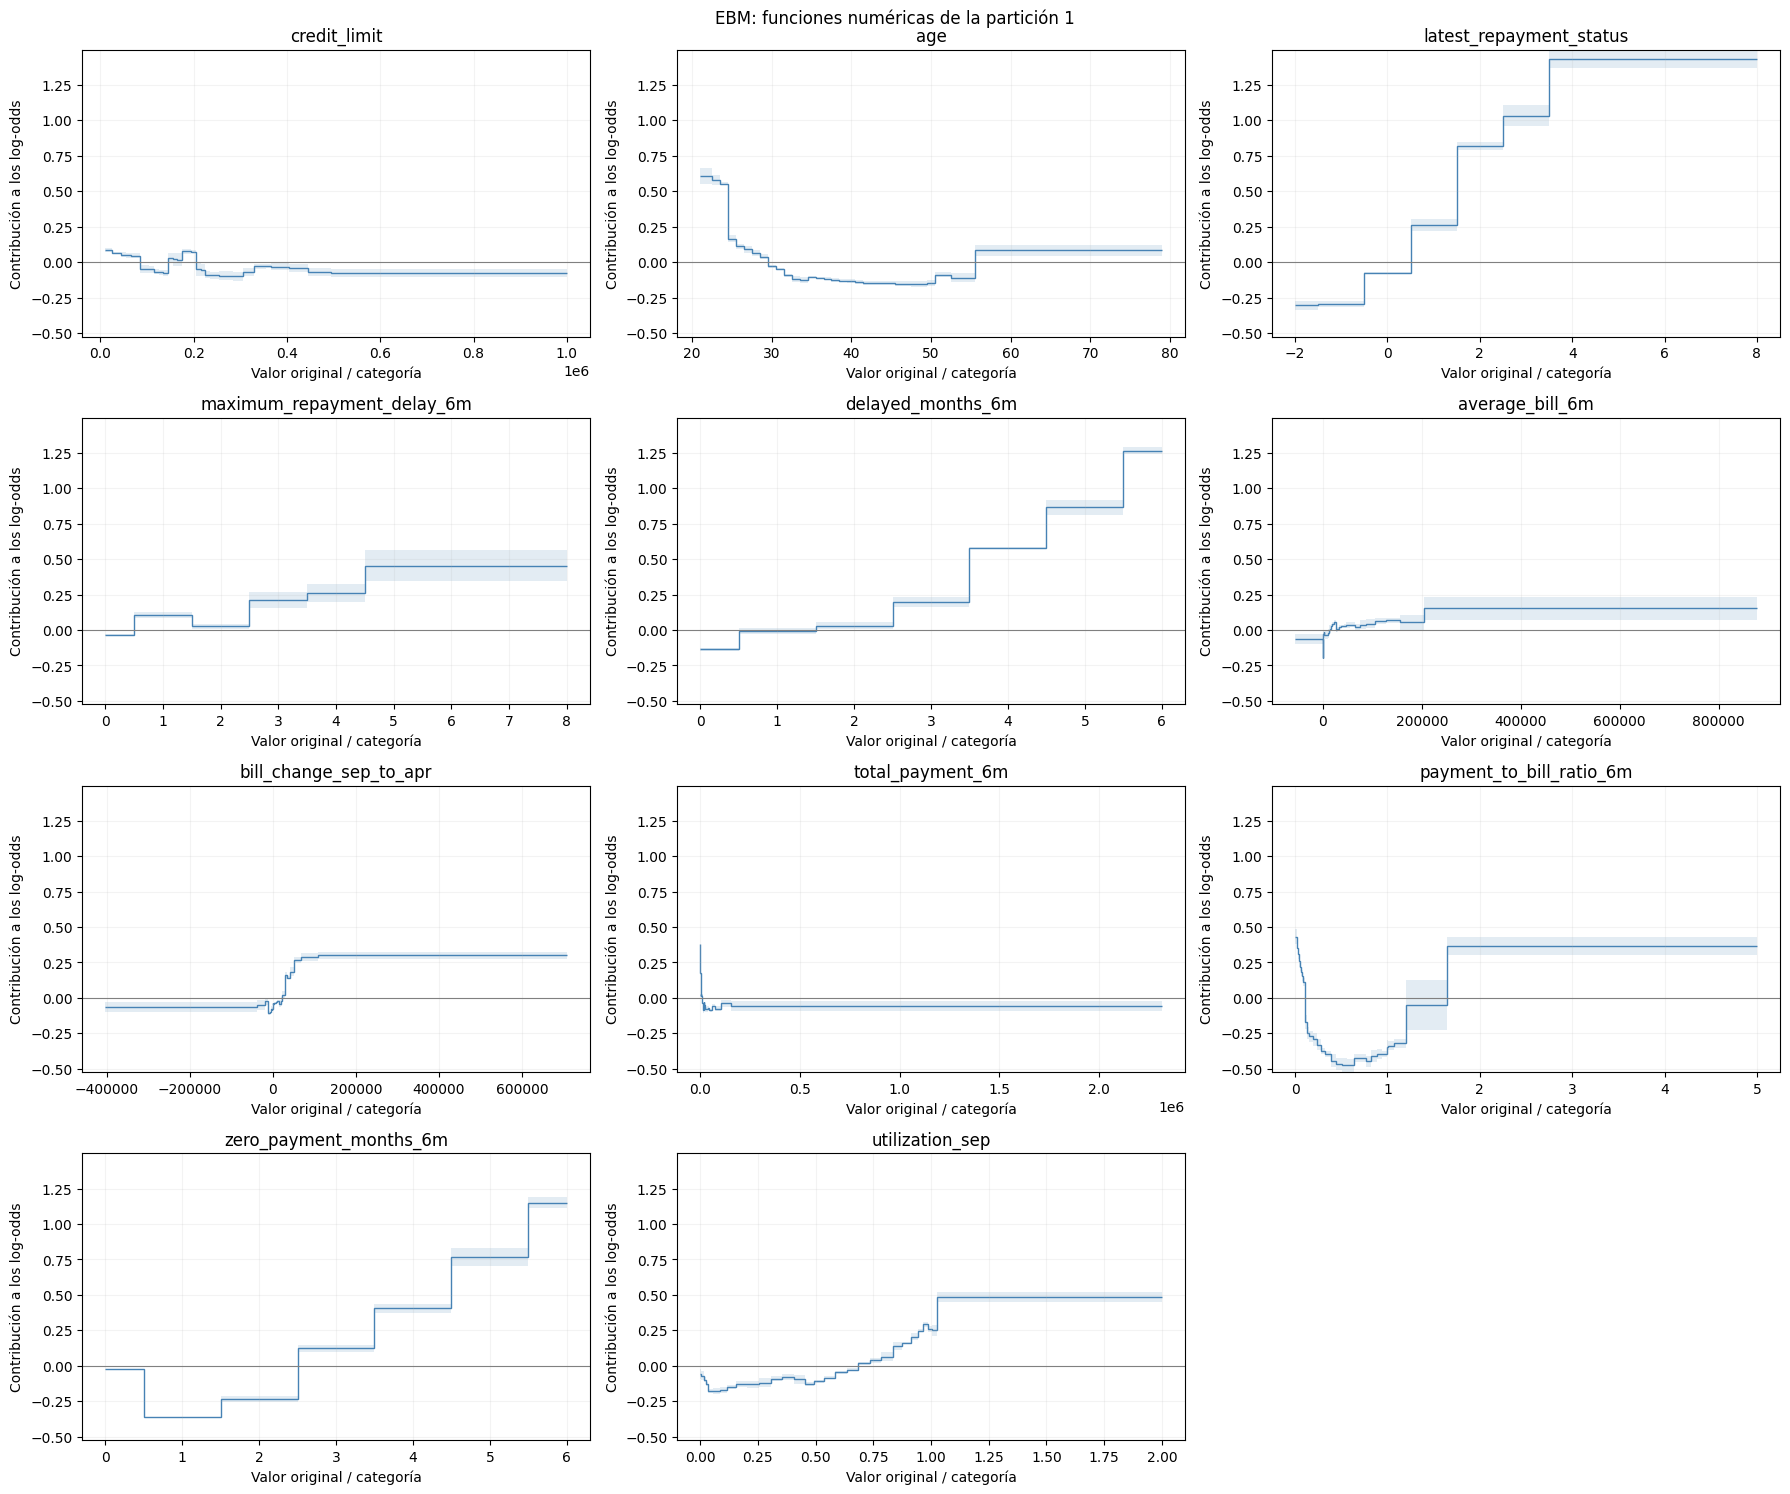

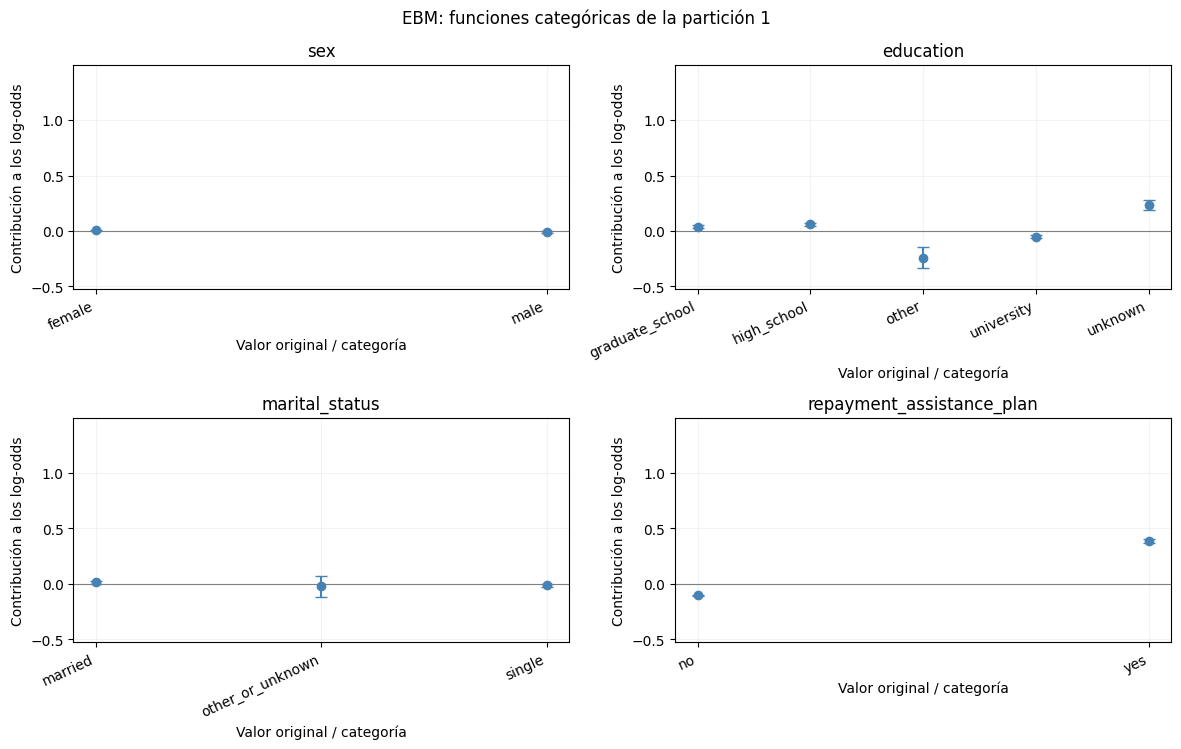

In [39]:
ebm_term_data = {
    name: ebm_global_explanation.data(term_idx)
    for term_idx, name in enumerate(ebm_reference_model.term_names_)
}


def plot_ebm_functions(variables, title, ncols):
    nrows = int(np.ceil(len(variables) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.8 * nrows), squeeze=False)
    for ax, variable in zip(axes.flat, variables):
        data = ebm_term_data[variable]
        scores = np.asarray(data["scores"], dtype=float)
        lower = data["lower_bounds"]
        upper = data["upper_bounds"]
        if variable in numeric_features:
            edges = np.asarray(data["names"], dtype=float)
            ax.stairs(scores, edges, baseline=None, color="steelblue")
            if lower is not None and upper is not None:
                ax.stairs(np.asarray(upper), edges, baseline=np.asarray(lower),
                          fill=True, alpha=0.15, color="steelblue")
        else:
            labels = data["names"]
            positions = np.arange(len(labels))
            errors = None if lower is None else np.vstack([
                scores - np.asarray(lower), np.asarray(upper) - scores
            ])
            ax.errorbar(positions, scores, yerr=errors, fmt="o", capsize=4, color="steelblue")
            ax.set_xticks(positions, labels=labels, rotation=25, ha="right")
        ax.axhline(0, color="gray", linewidth=0.8)
        ax.set_ylim(data["scores_range"])
        ax.set(title=variable, xlabel="Valor original / categoría", ylabel="Contribución a los log-odds")
        ax.grid(alpha=0.15)
    for ax in list(axes.flat)[len(variables):]:
        ax.set_visible(False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_ebm_functions(numeric_features, "EBM: funciones numéricas de la partición 1", ncols=3)
plot_ebm_functions(categorical_features, "EBM: funciones categóricas de la partición 1", ncols=2)

Las funciones numéricas confirman que la relación con la dificultad no puede resumirse siempre mediante un único signo. El cociente entre pagos y facturas disminuye su contribución en la región baja e intermedia y la aumenta en la región alta; la edad tiene mayor contribución en los más jóvenes, una región adulta de contribución negativa y un aumento en el tramo superior. En meses sin pago, los valores 1 y 2 tienen contribuciones menores que cero meses, mientras que a partir de 3 la contribución es positiva y creciente en este ajuste. Son formas del modelo, no afirmaciones sobre intervenciones.

La revisión de las demás funciones añade matices:

| Variable o grupo | Lectura de la función de la partición 1 |
| --- | --- |
| `latest_repayment_status` y `delayed_months_6m` | Las contribuciones aumentan en términos generales con los códigos positivos y la acumulación de meses con retraso. Los intervalos altos agrupan varios valores; sus mesetas no demuestran una equivalencia real entre esos estados. |
| `maximum_repayment_delay_6m` | La función no es completamente monótona y presenta contribuciones positivas en retrasos elevados. Su menor contribución global y la correlación con otros resúmenes aconsejan una interpretación conjunta. |
| `utilization_sep` | La contribución es principalmente negativa en la región baja e intermedia y aumenta hacia valores próximos o superiores a 1. No se identifica un efecto causal de incrementar la utilización. |
| `credit_limit` | Alterna pequeñas contribuciones positivas y negativas en la región baja e intermedia y se mantiene negativa en la región alta del ajuste. No reproduce un efecto lineal uniforme del límite. |
| `average_bill_6m` y `bill_change_sep_to_apr` | Muestran variaciones alrededor de los importes habituales y contribuciones positivas en algunos intervalos altos. Los rangos extremos comprimen los detalles de la figura; se requiere consultar la vista interactiva y su distribución. |
| `total_payment_6m` | La contribución es positiva para pagos nulos o muy pequeños y queda próxima a cero, ligeramente negativa, en una amplia región posterior. El ancho de la última meseta procede de los bins, no de evidencia uniforme para todos los importes elevados. |
| `education` | `unknown` es positiva y `other` negativa en este modelo, mientras que las categorías más frecuentes tienen contribuciones más próximas a cero. Los niveles poco frecuentes no justifican conclusiones generales sobre educación. |
| `sex` y `marital_status` | Sus contribuciones son pequeñas respecto a los principales términos. Esto no demuestra ausencia de sesgos ni equidad. |
| `repayment_assistance_plan` | La separación entre `yes` y `no` es clara en el ajuste, pero debe entenderse considerando la asignación selectiva del plan. |

Las regiones con pocos registros y las bandas de variación requieren cautela. Una banda estrecha entre cuatro réplicas tampoco garantiza que la función sea correcta fuera del conjunto. Las numéricas conservan sus unidades originales, lo que permite relacionar los intervalos con el diccionario sin confundirlos con una probabilidad aislada.

### <a id="sec-8-7"></a> 8.7. Variabilidad de las contribuciones globales

Se compara la media absoluta de contribución de cada variable en los cinco modelos. La tabla y los puntos muestran si el orden y la magnitud son consistentes. Esta comparación combina variaciones del ajuste, de sus configuraciones y de las distribuciones de entrenamiento utilizadas para ponderar las contribuciones.

Una importancia media similar no garantiza una función con la misma forma o signo. Por eso la siguiente subsección compara también muestras de las funciones. Con cinco entrenamientos solapados, las cajas son resúmenes descriptivos y no intervalos de confianza.

,Media,Desviación típica,Mínimo,Máximo
payment_to_bill_ratio_6m,0.3072,0.0103,0.2931,0.3182
latest_repayment_status,0.2270,0.0112,0.2166,0.2445
zero_payment_months_6m,0.1961,0.0233,0.1711,0.2272
delayed_months_6m,0.1899,0.0085,0.1814,0.2022
repayment_assistance_plan,0.1656,0.0087,0.1530,0.1739
age,0.1535,0.0050,0.1474,0.1596
utilization_sep,0.1379,0.0158,0.1155,0.1580
total_payment_6m,0.0901,0.0093,0.0760,0.1006
bill_change_sep_to_apr,0.0822,0.0088,0.0717,0.0943
maximum_repayment_delay_6m,0.0533,0.0107,0.0422,0.0685


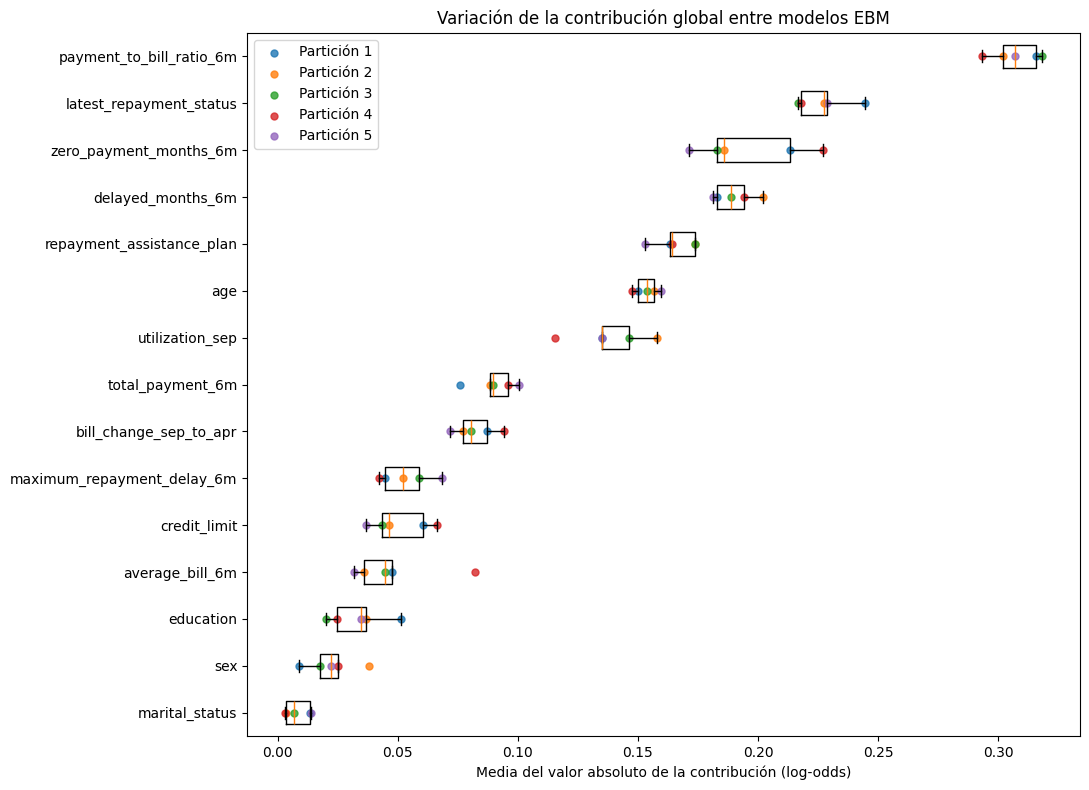

In [37]:
ebm_importance_by_fold = pd.DataFrame([
    pd.Series(pipeline["model"].term_importances(), index=pipeline["model"].term_names_, name=fold)
    for fold, pipeline in enumerate(ebm_models, start=1)
])
ebm_importance_by_fold.index.name = "Partición"
ebm_importance_stability = pd.DataFrame({
    "Media": ebm_importance_by_fold.mean(),
    "Desviación típica": ebm_importance_by_fold.std(ddof=1),
    "Mínimo": ebm_importance_by_fold.min(),
    "Máximo": ebm_importance_by_fold.max(),
}).sort_values("Media", ascending=False)
display(ebm_importance_stability.round(4))

plot_variables = ebm_importance_stability.index[::-1]
positions = np.arange(1, len(plot_variables) + 1)
fig, ax = plt.subplots(figsize=(11, 8))
ax.boxplot([ebm_importance_by_fold[variable].dropna().to_numpy() for variable in plot_variables],
           vert=False, positions=positions, showfliers=False)
for fold in ebm_importance_by_fold.index:
    ax.scatter(ebm_importance_by_fold.loc[fold, plot_variables], positions,
               s=25, alpha=0.8, label=f"Partición {fold}")
ax.set_yticks(positions, labels=plot_variables)
ax.set(title="Variación de la contribución global entre modelos EBM",
       xlabel="Media del valor absoluto de la contribución (log-odds)")
ax.legend()
plt.tight_layout()
plt.show()

El **cociente entre pagos y facturas tiene la mayor contribución global en los cinco modelos**: su mínimo (0,2931) supera el máximo observado de cualquiera de las demás variables. Su media es 0,3072 y su desviación típica 0,0103. El estado reciente de pago mantiene una contribución elevada (media 0,2270; desviación 0,0112).

Los meses sin pago (0,1961; desviación 0,0233) y los meses con retraso (0,1899; desviación 0,0085) tienen magnitudes próximas, pero el primero varía más. No debe fijarse un orden universal entre ambos a partir de la partición 1. El plan de asistencia mantiene una media 0,1656 y desviación 0,0087, y la edad 0,1535 y 0,0050.

Entre los términos de menor magnitud, `average_bill_6m` muestra variación apreciable: de 0,0318 a 0,0822. `sex` varía entre 0,0089 y 0,0381, aunque permanece muy por debajo de las principales contribuciones. La estabilidad del núcleo de variables es descriptiva; los cinco entrenamientos se solapan y los valores absolutos no informan por sí solos de la estabilidad de sus signos o formas.

### <a id="sec-8-8"></a> 8.8. Comparación de las funciones en valores comunes

Se examinan las cinco variables con mayor contribución global en la partición 1 y la edad, cuya forma presenta cambios de dirección. La selección es descriptiva y no utiliza las métricas externas para cambiar los modelos. Se evalúan sus términos sobre los mismos valores originales: todos los niveles observados en las categóricas y variables con pocos valores, o 21 cuantiles del entrenamiento de la partición 1 para las numéricas de mayor cardinalidad.

`eval_terms` devuelve las contribuciones de los términos, sin intercepto. Las líneas entre muestras numéricas sirven de guía y no reproducen necesariamente todos los saltos de los bins de cada modelo. Los niveles nominales se dibujan como puntos separados, sin imponerles orden. Las funciones están centradas con entrenamientos diferentes; un desplazamiento pequeño puede reflejar ese centrado además de cambios en su forma.

Para evaluar un término se crean entradas de sondeo cambiando solo esa variable respecto a una fila base. **No son clientes nuevos ni ejemplos de intervenciones**: únicamente permiten consultar cada función aditiva, sin interpretar la probabilidad completa de esas combinaciones.

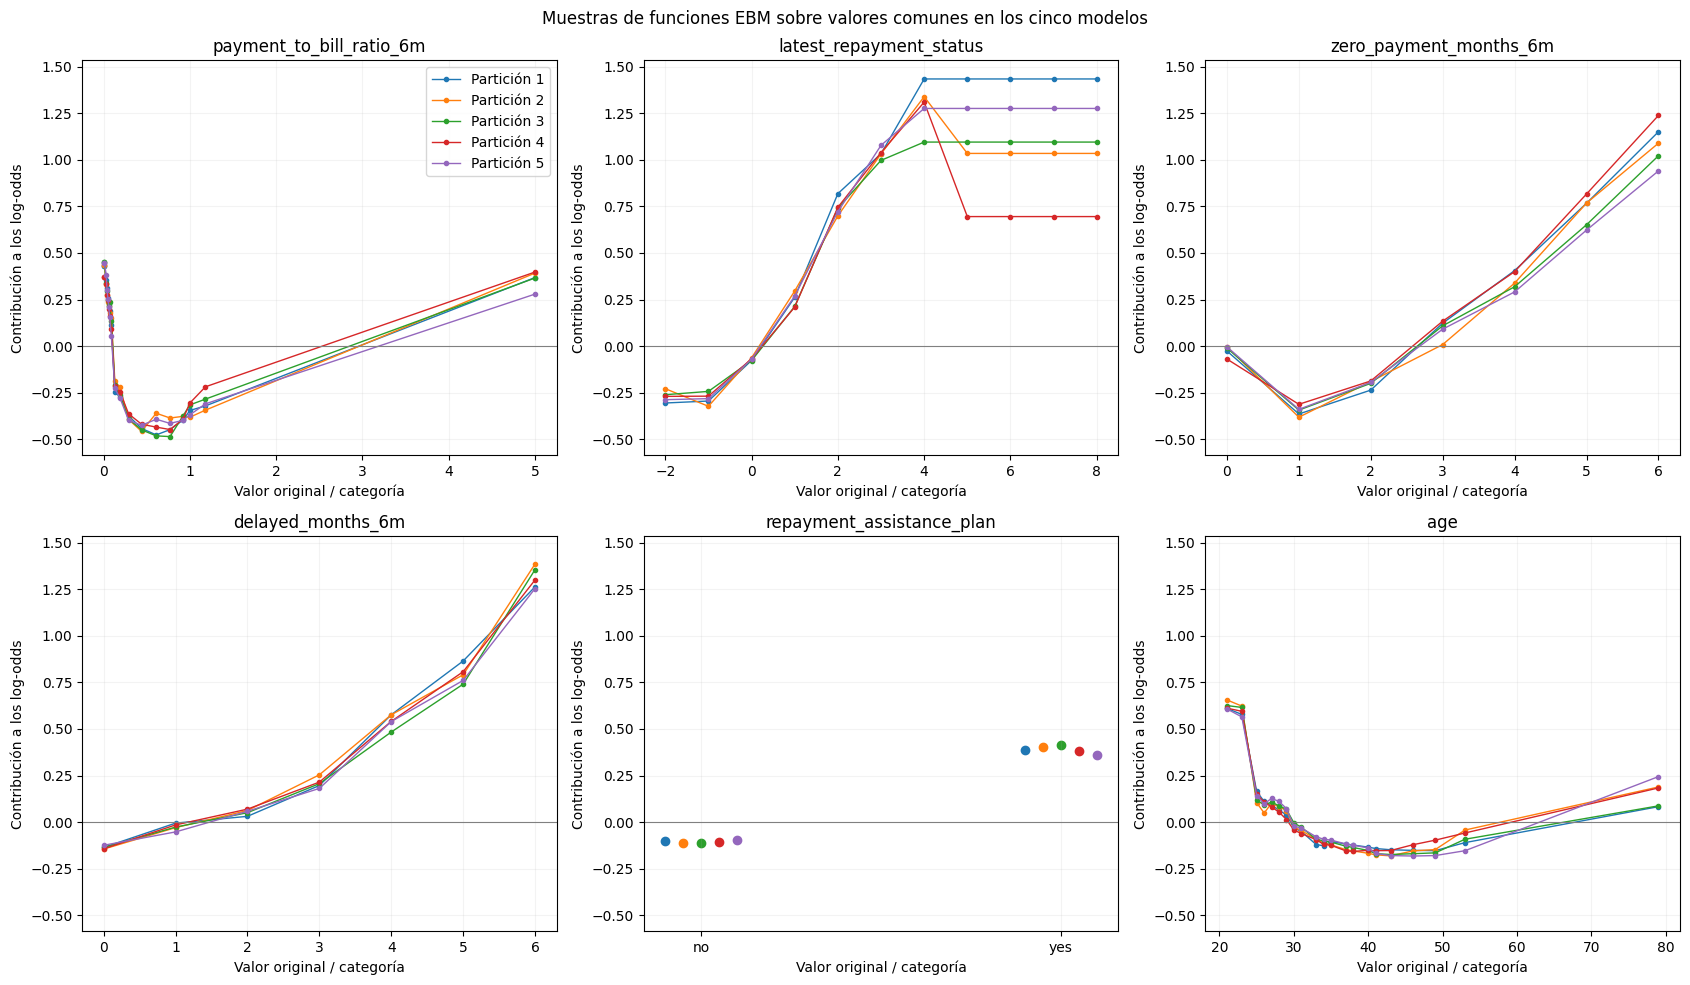

In [38]:
EBM_CURVE_VARIABLES = list(dict.fromkeys(
    ebm_global_importance["Variable"].head(5).tolist() + ["age"]
))
ebm_probe_train = X_raw.iloc[cv_splits[EBM_REFERENCE_FOLD - 1][0]]
ebm_curve_comparison = {}
for variable in EBM_CURVE_VARIABLES:
    observed = ebm_probe_train[variable].dropna()
    if variable in categorical_features or observed.nunique() <= 20:
        grid = sorted(observed.unique())
    else:
        grid = np.unique(np.quantile(observed, np.linspace(0, 1, 21)))
    probe = pd.concat([ebm_probe_train.iloc[[0]]] * len(grid), ignore_index=True)
    probe[variable] = grid
    table = pd.DataFrame({"Valor": grid})
    for fold, pipeline in enumerate(ebm_models, start=1):
        model = pipeline["model"]
        feature_idx = list(model.feature_names_in_).index(variable)
        term_idx = next(i for i, features in enumerate(model.term_features_)
                        if tuple(features) == (feature_idx,))
        table[f"Partición {fold}"] = model.eval_terms(pipeline["preprocess"].transform(probe))[:, term_idx]
    ebm_curve_comparison[variable] = table

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
colors = plt.cm.tab10(np.arange(N_SPLITS))
all_values = np.concatenate([
    table.drop(columns="Valor").to_numpy().ravel() for table in ebm_curve_comparison.values()
])
y_limits = (all_values.min() - 0.1, all_values.max() + 0.1)
for ax, variable in zip(axes.flat, EBM_CURVE_VARIABLES):
    table = ebm_curve_comparison[variable]
    for fold in range(1, N_SPLITS + 1):
        scores = table[f"Partición {fold}"]
        if variable in categorical_features:
            positions = np.arange(len(table)) + (fold - 3) * 0.05
            ax.scatter(positions, scores, color=colors[fold - 1], label=f"Partición {fold}")
            ax.set_xticks(np.arange(len(table)), labels=table["Valor"])
        else:
            ax.plot(table["Valor"], scores, marker=".", linewidth=1,
                    color=colors[fold - 1], label=f"Partición {fold}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_ylim(y_limits)
    ax.set(title=variable, xlabel="Valor original / categoría", ylabel="Contribución a los log-odds")
    ax.grid(alpha=0.15)
for ax in list(axes.flat)[len(EBM_CURVE_VARIABLES):]:
    ax.set_visible(False)
axes.flat[0].legend()
fig.suptitle("Muestras de funciones EBM sobre valores comunes en los cinco modelos")
plt.tight_layout()
plt.show()

Las muestras sobre valores comunes muestran un **núcleo de formas consistente entre los cinco modelos**, con diferencias de magnitud y algunas discrepancias locales:

- **Cociente entre pagos y facturas:** todos los modelos muestran contribución positiva para valores muy bajos, negativa en la región intermedia y positiva en el extremo alto representado. La no monotonía se reproduce en los cinco ajustes. El tramo dibujado entre las últimas muestras es una guía visual: no demuestra crecimiento lineal entre esos valores ni localiza todos los saltos de los bins.
- **Estado reciente de pago:** los modelos son próximos para los códigos habituales y se separan más en los elevados. En la partición 4, la contribución disminuye al pasar del código 4 al 5, mientras que otros ajustes mantienen mesetas distintas. No puede afirmarse que la función sea creciente en todos los códigos y entrenamientos. Los valores altos poco frecuentes requieren especial cautela.
- **Meses sin pago:** la contribución de un mes sin pago es menor que la de cero meses en todos los ajustes, y las contribuciones crecen al acumular varios meses. La diferencia entre modelos es más visible en los recuentos altos. Este patrón condicional no prueba que un mes sin pago proteja frente a la dificultad.
- **Meses con retraso:** los cinco modelos presentan un aumento de contribución al acumular retrasos, con mayor separación en los valores altos. No se interpreta como un efecto independiente del retraso máximo o del estado reciente.
- **Plan de asistencia:** `no` se mantiene con contribución negativa y `yes` con positiva en todos los modelos. La asociación es consistente en estos ajustes y sigue sin identificar el efecto causal de recibir asistencia.
- **Edad:** se repite la contribución elevada en las edades más jóvenes, una región adulta de contribución negativa y un aumento hacia el tramo superior. La magnitud de este último difiere entre modelos y las edades extremas tienen menor respaldo de datos.

Esta comparación respalda la repetición de algunas formas en el ejercicio, pero no su validez causal ni poblacional. No se han cambiado las funciones para imponer monotonicidad o hacerlas coincidir con una expectativa previa.

### <a id="sec-8-9"></a> 8.9. Síntesis de la interpretación y limitaciones

EBM conserva una estructura de 15 términos univariantes sin interacciones y permite explicar la predicción como suma de contribuciones en log-odds. Las funciones muestran umbrales, mesetas y cambios de dirección que la representación logística lineal no recoge del mismo modo. El cociente entre pagos y facturas presenta la mayor media absoluta de contribución en los cinco ajustes; junto al estado reciente, los meses sin pago y los meses con retraso, constituye una parte consistente de la explicación global.

La estabilidad no es uniforme. Las categorías poco frecuentes, los estados de retraso elevados y las edades o importes extremos necesitan cautela. Los resúmenes correlacionados pueden repartirse la información de distintas formas, y ni sus curvas ni su clasificación por contribución identifican efectos independientes. La asociación positiva del plan de asistencia se mantiene, pero no autoriza a concluir que el plan cause perjuicio.

La evaluación externa obtiene ROC-AUC media 0,7755. El umbral ajustado favorece la detección y la exactitud equilibrada a costa de precisión y exactitud total. La explicabilidad aporta información adicional a esas métricas: permite identificar relaciones no monótonas, discrepancias entre modelos y regiones cuyo respaldo es limitado. No garantiza causalidad, equidad, calibración ni validez fuera del conjunto semisintético.

La interpretación global de EBM queda documentada. La comparación conjunta de rendimiento se desarrollará en el apartado 9 y las explicaciones locales para casos comunes en el 10. No se ha seleccionado todavía una familia final ni se ha utilizado el test sin etiquetas para ajustar decisiones.

[Volver al índice](#indice)

## <a id="sec-9"></a> 9. Comparación del rendimiento

## <a id="sec-10"></a> 10. Interpretación local comparada

## <a id="sec-11"></a> 11. Discusión de las explicaciones

## <a id="sec-12"></a> 12. Selección y entrenamiento final

## <a id="sec-13"></a> 13. Predicción y exportación del test

## <a id="sec-14"></a> 14. Conclusiones

## <a id="sec-15"></a> 15. Referencias y uso de IA generativa